# Research Paper Recommendation — Machine Learning vs Deep Learning
## Implementation, accuracy and comparative analysis

**Course project — Mathematical Foundations for Computer Science · Group 05**

This notebook implements the complete project in one place and is organised around three questions:

| Part | Question | What it contains |
|---|---|---|
| **Part 0** | What is common to both? | data, preprocessing, ground truth, metrics, the evaluation protocol |
| **Part 1** | **Machine learning** — how accurate is it? | TF-IDF, SVD (Latent Semantic Analysis), ridge least squares; implementation, accuracy, analysis |
| **Part 2** | **Deep learning** — how accurate is it? | pretrained transformer encoders; implementation, accuracy, analysis |
| **Part 3** | **How do they compare?** | accuracy, statistical significance, per-domain and per-query behaviour, efficiency, example outputs, conclusions |

### The task

Given a paper (or a free-text query), recommend the 10 most related papers from a corpus of 9,956 computer-science
papers. Every method follows the same recipe — **turn each paper into a vector, then rank by cosine similarity** —
and they differ only in *how the vector is built*.

### What "accuracy" means here

A recommender returns a ranked list, not a single class, so there is no single accuracy number. We report the
standard ranking metrics and use **Precision@10** — the share of the 10 recommended papers that are relevant — as
the headline "accuracy". A recommended paper counts as relevant if it shares at least one OpenAlex topic with the
query paper (Part 0 explains this ground truth).

### The methods

| Family | Code | Method | Uses topic labels for training? |
|---|---|---|---|
| Machine learning | **A** | TF-IDF + cosine similarity (baseline) | no |
| Machine learning | **B** | TF-IDF → truncated SVD (rank $k$) | no |
| Machine learning | **B+** | hybrid of A and B | no |
| Machine learning | **C** | SVD → ridge least squares → second SVD ("learned metric") | yes |
| Machine learning | **D** | fusion of C and A | yes |
| Deep learning | **E1–E3** | one pretrained transformer encoder (MiniLM, SPECTER, BGE) | no |
| Deep learning | **E** | the three encoders combined | no |
| Deep learning | **F−** | transformer embeddings → ridge least squares → SVD | yes |
| Deep learning + ML | **F** | [transformer embeddings, SVD vector] → ridge least squares → SVD | yes |
| Deep learning + ML | **G** | fusion of F and E | yes |


### Headline results (6,911 held-out test queries)

| | Best machine-learning model (D) | Best deep-learning model (G) | Difference |
|---|---:|---:|---:|
| **Precision@10** ("accuracy") | 0.801 | **0.881** | +0.079 |
| Precision@1 | 0.855 | **0.929** | +0.074 |
| MRR | 0.891 | **0.948** | +0.057 |
| nDCG@10 | 0.813 | **0.892** | +0.079 |
| Hit@10 | 0.954 | **0.982** | +0.028 |

For reference, the TF-IDF baseline scores Precision@10 = 0.699 and a random ranking 0.075. Deep learning is more
accurate on every metric and in every research domain; machine learning is far cheaper, fully transparent and needs
no external model. The most practical system combines the two: deep features, a classical least-squares head and
an SVD compression (model F: Precision@10 = 0.874 in 300 dimensions, about 60× faster to query than TF-IDF).

---
# Part 0 — Common foundation

Everything in this part is shared by the machine-learning and the deep-learning models, so that the comparison in
Part 3 is like-for-like: **same corpus, same queries, same ground truth, same metrics, same evaluation code.**

## 0.1 Setup

**What the code does** — imports NumPy/SciPy (linear algebra), pandas (tables), matplotlib (charts), scikit-learn
(TF-IDF, truncated SVD) and NLTK (stemmer); fixes the random seed so that every number is reproducible; sets one
chart style.

In [1]:
import os, re, time, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scipy.linalg as sla
from scipy import stats
from scipy.sparse.linalg import svds
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from nltk.stem import PorterStemmer

warnings.filterwarnings("ignore")
SEED = 42
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

# One consistent chart style for the whole notebook.
BLUE, ORANGE, AQUA, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#8a8985"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b9b8b2", "axes.labelcolor": "#52514e", "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelsize": 9.5, "xtick.color": "#52514e", "ytick.color": "#52514e",
    "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.markersize": 6,
})
print("Libraries loaded.")

Libraries loaded.


## 0.2 Dataset

9,958 research papers collected from **OpenAlex** across six computer-science domains, with
`paper_id, title, abstract, authors, year, venue, topics, doi, domain`.

- The **input** of every model is the text `title + abstract`.
- The **`topics`** column (three OpenAlex topics per paper) is never an input feature. It defines the ground truth
  and, for the supervised models (C, D, F−, F, G), provides training labels under a strict protocol (§0.5).

**What the code does** — loads the CSV, drops the two papers without an abstract, builds the `text` column, prints
data-quality facts, and plots three views of the corpus.

In [2]:
DATA_PATH = next(p for p in ["../data/research_papers.csv", "data/research_papers.csv"] if os.path.exists(p))
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)

df = df.dropna(subset=["abstract"]).reset_index(drop=True)      # papers without an abstract cannot be vectorised
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["text"] = df["title"].fillna("") + ". " + df["abstract"].fillna("")   # the document = title + abstract
N = len(df)

print("Usable papers:", N)
print("Missing values per column:", {c: int(v) for c, v in df.isna().sum().items() if v})
print("Papers with an identical abstract to another paper:", int(df["abstract"].duplicated().sum()))
df[["title", "authors", "year", "venue", "domain", "topics"]].head(3)

Raw shape: (9958, 9)
Usable papers: 9956
Missing values per column: {'authors': 164, 'year': 29, 'venue': 693, 'topics': 39, 'doi': 1800}
Papers with an identical abstract to another paper: 104


,title,authors,year,venue,domain,topics
0,Machine learning and deep learning,Christian Janiesch; Patrick Zschech; Kai Heinrich,2021.0,Electronic Markets,Machine Learning,Artificial Intelligence Applications; Neural Networks and Applications; Impact of AI a...
1,Machine learning in bioinformatics,Pedro Larrañaga; Borja Calvo; Roberto Santana; Concha Bielza; Josu Galdiano; Iñaki Inz...,2006.0,Briefings in Bioinformatics,Machine Learning,Machine Learning in Bioinformatics; Genomics and Phylogenetic Studies; Gene expression...
2,An Introduction to Machine Learning,Solveig Badillo; Balázs Bánfai; Fabian Birzele; Iakov I. Davydov; Lucy G. Hutchinson; ...,2020.0,Clinical Pharmacology & Therapeutics,Machine Learning,Machine Learning in Healthcare; Computational Drug Discovery Methods; Artificial Intel...


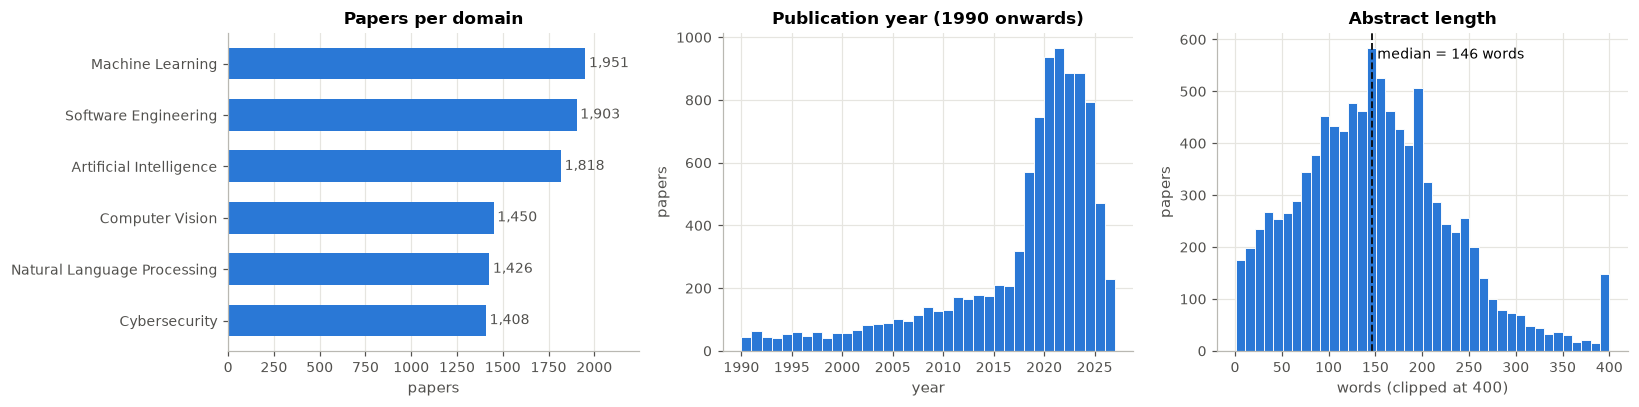

Domains: Machine Learning, Software Engineering, Artificial Intelligence, Computer Vision, Natural Language Processing, Cybersecurity


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

dc = df["domain"].value_counts().sort_values()
ax[0].barh(dc.index, dc.values, color=BLUE, height=0.62)
for y, v in enumerate(dc.values):
    ax[0].text(v + 20, y, f"{v:,}", va="center", fontsize=9, color="#52514e")
ax[0].set_title("Papers per domain"); ax[0].set_xlabel("papers"); ax[0].grid(axis="y", visible=False)
ax[0].set_xlim(0, dc.max() * 1.15)

yr = df["year"].dropna(); yr = yr[(yr >= 1990) & (yr <= 2026)]
ax[1].hist(yr, bins=np.arange(1990, 2028), color=BLUE, edgecolor="white", linewidth=0.6)
ax[1].set_title("Publication year (1990 onwards)"); ax[1].set_xlabel("year"); ax[1].set_ylabel("papers")

alen = df["abstract"].str.split().apply(len)
ax[2].hist(alen.clip(upper=400), bins=40, color=BLUE, edgecolor="white", linewidth=0.6)
ax[2].axvline(alen.median(), color="#0b0b0b", lw=1.2, ls="--")
ax[2].text(alen.median() + 6, ax[2].get_ylim()[1] * 0.92, f"median = {int(alen.median())} words", fontsize=9)
ax[2].set_title("Abstract length"); ax[2].set_xlabel("words (clipped at 400)"); ax[2].set_ylabel("papers")

plt.tight_layout(); plt.show()
print("Domains:", ", ".join(dc.index[::-1]))

## 0.3 Text preprocessing (used by the machine-learning models)

| Step | Example | Why |
|---|---|---|
| lower-casing | `Deep Learning` → `deep learning` | case carries no topical meaning |
| tokenisation (letters only) | `GPT-4, 2023!` → `gpt` | removes punctuation and digits |
| stop-word removal | drop `the, of, and…` | words that occur everywhere discriminate nothing |
| drop tokens of length ≤ 2 | drop `we`, `an` | mostly noise |
| Porter stemming | `learning, learned, learns` → `learn` | merges word forms into one dimension |

The deep-learning encoders of Part 2 do **not** use this step: they read the raw text with their own sub-word
tokeniser, because word order and word forms are information to them.

**What the code does** — `preprocess(text)` applies the five steps; it is mapped over all papers.

In [4]:
stemmer = PorterStemmer()
_token  = re.compile(r"[a-z]+")            # a token = a run of letters (drops punctuation and digits)
_stop   = set(ENGLISH_STOP_WORDS)          # scikit-learn's English stop-word list

def preprocess(text: str) -> str:
    '''lowercase -> tokenise -> remove stop-words / short tokens -> Porter stemming.'''
    return " ".join(stemmer.stem(w) for w in _token.findall(str(text).lower())
                    if w not in _stop and len(w) > 2)

t0 = time.time()
df["clean"] = df["text"].map(preprocess)
print("Preprocessed %d documents in %.1fs" % (N, time.time() - t0))
print("\nBEFORE:", df["text"].iloc[0][:140], "...")
print("AFTER :", df["clean"].iloc[0][:140], "...")

Preprocessed 9956 documents in 5.8s

BEFORE: Machine learning and deep learning. Abstract Today, intelligent systems that offer artificial intelligence capabilities often rely on machin ...
AFTER : machin learn deep learn abstract today intellig system offer artifici intellig capabl reli machin learn machin learn describ capac system le ...


## 0.4 Ground truth and the validation / test split

There are no human relevance judgements, so relevance is derived from the topics: **two papers are relevant to each
other if they share at least one topic.** With the paper–topic incidence matrix $T \in \{0,1\}^{m \times 1846}$ the
relevance matrix is $R = [\,TT^{\mathsf T} > 0\,]$.

The 9,911 papers that have at least one relevant paper are used as queries and split once, at random:

- **3,000 validation queries** — used to choose every hyper-parameter;
- **6,911 test queries** — used only to report accuracy. No setting in this notebook was chosen on them.

A random ranking would score Precision@10 ≈ 0.075, which is the floor against which all numbers should be read.

**What the code does** — builds $T$ and the boolean relevance matrix `REL`, counts the relevant papers per query,
and creates the `VAL` / `TEST` split.

In [5]:
# ---- topic incidence matrix T (papers x topics) and relevance matrix REL = [T T^T > 0] ------------
topic_lists = df["topics"].fillna("").map(lambda s: [t.strip().lower() for t in s.split(";") if t.strip()])
topic_names = np.array(sorted({t for ts in topic_lists for t in ts}))
topic_id = {t: i for i, t in enumerate(topic_names)}
rows_, cols_ = zip(*[(i, topic_id[t]) for i, ts in enumerate(topic_lists) for t in ts])
T = sp.csr_matrix((np.ones(len(rows_), dtype=np.float32), (rows_, cols_)), shape=(N, len(topic_names)))

REL = (T @ T.T).toarray() > 0            # REL[i, j] = True  <=>  papers i and j share >= 1 topic
np.fill_diagonal(REL, False)
N_REL = REL.sum(axis=1)                  # number of relevant papers for each query

# ---- validation / test split of the query papers ---------------------------------------------------
usable = np.where(N_REL > 0)[0]
perm = np.random.default_rng(SEED).permutation(usable)
VAL, TEST = np.sort(perm[:3000]), np.sort(perm[3000:])

print("Distinct topics: %d" % len(topic_names))
print("Papers with topics: %d   |   usable query papers: %d" % (int((T.sum(axis=1) > 0).sum()), len(usable)))
print("Validation queries: %d   |   Test queries: %d" % (len(VAL), len(TEST)))
print("Relevant papers per query: median %d, mean %.0f" % (np.median(N_REL[usable]), N_REL[usable].mean()))
print("Expected Precision of a RANDOM ranking = mean(#relevant / (m-1)) = %.4f" % (N_REL[TEST] / (N - 1)).mean())

Distinct topics: 1846
Papers with topics: 9917   |   usable query papers: 9911
Validation queries: 3000   |   Test queries: 6911
Relevant papers per query: median 819, mean 749
Expected Precision of a RANDOM ranking = mean(#relevant / (m-1)) = 0.0753


## 0.5 Metrics and the evaluation routine

For a query with ranked recommendations $d_1, d_2, \dots$ and relevance indicators $\mathrm{rel}_i \in \{0,1\}$:

| Metric | Formula | Question it answers |
|---|---|---|
| **P@1** | $\mathrm{rel}_1$ | is the single best recommendation relevant? |
| **P@5, P@10** | $\frac1K\sum_{i \le K}\mathrm{rel}_i$ | what share of the top $K$ is relevant? (**P@10 = headline accuracy**) |
| **MRR** | $1/\text{rank of the first relevant result}$ | how early does the first good result appear? |
| **nDCG@10** | $\frac{\sum_{i \le 10}\mathrm{rel}_i/\log_2(i+1)}{\text{best achievable}}$ | precision that rewards putting relevant papers higher |
| **Hit@10** | $\max_{i \le 10}\mathrm{rel}_i$ | does the top 10 contain at least one relevant paper? |
| **R@10** | $\frac{1}{\#\text{relevant}}\sum_{i \le 10}\mathrm{rel}_i$ | share of all relevant papers retrieved (tiny here: a query has ≈800 relevant papers) |

**Protocol for models that learn from topic labels.** The labels that train the supervised models are the same kind
of labels that define relevance, so a paper's own labels must never influence its own score. The papers are divided
into 5 folds, and **to score a (query, candidate) pair the model is trained only on papers outside both the query's
fold and the candidate's fold** ("pairwise exclusion"; 15 models). Parts 1 and 2 each include a *leakage audit* that
shows what the score would be without this precaution.

**What the code does**

- `evaluate(sim_fn, queries)` — the single evaluation routine used for every model. `sim_fn(q)` returns the
  similarity of each query in `q` to all papers; the routine masks the query itself, takes the top 10 and returns
  the seven metrics for every query.
- `register(name, sim_fn, dims, family)` — evaluates a model on the **test** queries and stores the per-query scores.
- `boot_ci` — bootstrap 95% confidence interval of a mean (queries resampled 1,000 times).
- `results_table(names)` — accuracy table with a confidence interval for P@10.
- `head_to_head(new, base)` — paired comparison of two models on the same queries: differences, confidence
  interval, paired t-test, and how many queries got better / stayed equal / got worse.

In [6]:
METRICS = ["P@5", "P@10", "R@10", "MRR", "nDCG@10", "P@1", "Hit@10"]
DISCOUNT = 1.0 / np.log2(np.arange(2, 12))                               # 1/log2(i+1) for ranks i = 1..10
IDEAL_DCG = np.array([DISCOUNT[:min(10, r)].sum() for r in N_REL])       # DCG of a perfect top-10

def evaluate(sim_fn, queries, chunk=500):
    '''Evaluate a similarity function.
       sim_fn(q) -> array (len(q), m): similarity of each query paper in q to every paper.
       Returns an array (len(queries), 7) with P@5, P@10, R@10, RR, nDCG@10, P@1 and Hit@10 for every query.'''
    out = []
    for s in range(0, len(queries), chunk):                              # process queries in chunks (memory)
        q = queries[s:s + chunk]
        S = np.asarray(sim_fn(q), dtype=np.float32)
        S[np.arange(len(q)), q] = -np.inf                                # a paper must not recommend itself
        top = np.argpartition(-S, 10, axis=1)[:, :10]                    # the 10 best per row (unordered)
        order = np.argsort(-np.take_along_axis(S, top, axis=1), axis=1)
        top = np.take_along_axis(top, order, axis=1)                     # ... now ordered best-first
        hit = REL[q[:, None], top]                                       # hit[i, j] = is the j-th result relevant?
        rr = np.where(hit.any(axis=1), 1.0 / (hit.argmax(axis=1) + 1), 0.0)
        out.append(np.c_[hit[:, :5].mean(axis=1),                        # P@5
                         hit.mean(axis=1),                               # P@10
                         hit.sum(axis=1) / N_REL[q],                     # R@10
                         rr,                                             # reciprocal rank
                         (hit * DISCOUNT).sum(axis=1) / IDEAL_DCG[q],    # nDCG@10
                         hit[:, 0],                                      # P@1: is the first result relevant?
                         hit.any(axis=1)])                               # Hit@10: any relevant result in the top 10?
    return np.vstack(out)

def summary(scores):
    return dict(zip(METRICS, scores.mean(axis=0)))

In [7]:
methods = {}        # name -> (similarity function, dimensions compared, family)
test_scores = {}    # name -> array (test queries x 7 metrics)
COL = {m_: i for i, m_ in enumerate(METRICS)}          # metric name -> column index

def register(name, sim_fn, dims, family):
    '''Evaluate a model on the held-out TEST queries and remember it.'''
    methods[name] = (sim_fn, dims, family)
    test_scores[name] = evaluate(sim_fn, TEST)

def boot_ci(x, B=1000, seed=SEED):
    '''Percentile bootstrap 95% confidence interval for the mean of x.'''
    r_ = np.random.default_rng(seed); nq = len(x)
    means = np.array([x[r_.integers(0, nq, nq)].mean() for _ in range(B)])
    return np.percentile(means, [2.5, 97.5])

def results_table(names):
    rows = []
    for nm in names:
        s = test_scores[nm]; lo, hi = boot_ci(s[:, COL["P@10"]])
        rows.append(dict(method=nm, family=methods[nm][2], dims=methods[nm][1], **summary(s),
                         **{"P@10 95% CI": "[%.3f, %.3f]" % (lo, hi)}))
    cols = ["family", "dims", "P@1", "P@5", "P@10", "P@10 95% CI", "MRR", "nDCG@10", "Hit@10", "R@10"]
    tab = pd.DataFrame(rows).set_index("method")[cols]
    return tab.style.format({**{c: "{:.4f}" for c in METRICS}, "dims": "{:,.0f}"}) \
              .highlight_max(subset=["P@1", "P@5", "P@10", "MRR", "nDCG@10", "Hit@10"], color="#d7e7fa")

def head_to_head(new, base):
    '''Paired comparison of model `new` against model `base` on the test queries.'''
    a, b = test_scores[new], test_scores[base]
    d = a[:, COL["P@10"]] - b[:, COL["P@10"]]
    lo, hi = boot_ci(d)
    p = stats.ttest_rel(a[:, COL["P@10"]], b[:, COL["P@10"]]).pvalue
    return {"P@10 (first)": b[:, COL["P@10"]].mean(), "P@10 (second)": a[:, COL["P@10"]].mean(),
            "Δ P@10": d.mean(), "95% CI of Δ": "[%+.3f, %+.3f]" % (lo, hi),
            "paired t-test p": "below 1e-300" if p < 1e-300 else "%.1e" % p,
            "Δ P@1": a[:, COL["P@1"]].mean() - b[:, COL["P@1"]].mean(),
            "Δ MRR": a[:, COL["MRR"]].mean() - b[:, COL["MRR"]].mean(),
            "Δ nDCG@10": a[:, COL["nDCG@10"]].mean() - b[:, COL["nDCG@10"]].mean(),
            "Δ Hit@10": a[:, COL["Hit@10"]].mean() - b[:, COL["Hit@10"]].mean(),
            "queries better / equal / worse": "%d / %d / %d" % ((d > 0).sum(), (d == 0).sum(), (d < 0).sum())}

print("Evaluation helpers ready.  Metrics:", METRICS)

Evaluation helpers ready.  Metrics: ['P@5', 'P@10', 'R@10', 'MRR', 'nDCG@10', 'P@1', 'Hit@10']


---
# Part 1 — Machine learning

## 1.1 The algorithms

Part 1 uses classical, fully transparent machine learning built from linear algebra. Nothing here is a neural
network; every step has a closed-form solution.

| Step | Algorithm | Type | Formula |
|---|---|---|---|
| A | **TF-IDF vector-space model** | unsupervised feature weighting | $w_{ij} = (1+\ln \mathrm{tf}_{ij})\,\bigl(\ln\frac{1+m}{1+\mathrm{df}_j}+1\bigr)$, rows scaled to unit length |
| – | **Cosine nearest neighbours** | retrieval | $s = A\,a_q^{\mathsf T}$, take the 10 largest entries |
| B | **Truncated SVD** (Latent Semantic Analysis) | unsupervised dimensionality reduction | $A \approx U_k\Sigma_kV_k^{\mathsf T}$, paper vector $z = aV_k$ |
| B+ | **Score fusion** | ensemble | $\alpha\,s_A + (1-\alpha)\,s_B$ |
| C | **Ridge regression** (regularised least squares) + **reduced-rank projection** | supervised metric learning | $W = (Z^{\mathsf T}Z+\lambda I)^{-1}Z^{\mathsf T}Y$, then $W = QSP^{\mathsf T}$, paper vector $x = zQ_rS_r$ |
| D | **Score fusion** | ensemble | $(1-\beta)\,s_C + \beta\,s_A$ |

## 1.2 Model A — TF-IDF + cosine similarity

Each paper becomes a row of the **term–document matrix** $A \in \mathbb{R}^{m \times n}$ ($m$ papers, $n$ terms).
Term frequency rewards words that are frequent in the paper; inverse document frequency rewards words that are rare
in the corpus; unit-length rows make the cosine similarity of two papers equal to their dot product. $A$ is stored
as a sparse matrix because a paper uses only about 100 of the 31,291 terms.

**What the code does** — fits the vectoriser (`min_df=5`, `max_df=0.5`, unigrams + bigrams, sub-linear tf),
reports shape and sparsity; then `recommend_tfidf(idx)` computes $A a_q^{\mathsf T}$ and returns the top-$k$ papers
for an example paper.

In [8]:
vectorizer = TfidfVectorizer(
    min_df=5,             # ignore terms that occur in fewer than 5 papers (typos, noise)
    max_df=0.5,           # ignore terms that occur in more than 50% of papers (carry no information)
    ngram_range=(1, 2),   # unigrams and bigrams
    sublinear_tf=True,    # tf -> 1 + ln(tf)
)                         # norm="l2" is the default: every row is scaled to unit length
t0 = time.time()
A = vectorizer.fit_transform(df["clean"]).tocsr()     # sparse term-document matrix, shape (m, n)
build_time_tfidf = time.time() - t0
A_T = A.T.tocsr()                                     # transpose, kept in CSR form for fast products
terms = vectorizer.get_feature_names_out()

m, n = A.shape
row_norms = np.sqrt(A.multiply(A).sum(axis=1)).A1
print("Term-document matrix A in R^(m x n)")
print("  m = %d documents,  n = %d terms" % (m, n))
print("  non-zeros: %d  (%.3f%% of the %d x %d entries)" % (A.nnz, 100 * A.nnz / (m * n), m, n))
print("  average distinct terms per paper: %.0f" % (A.nnz / m))
print("  rows are unit vectors: min norm %.6f, max norm %.6f" % (row_norms.min(), row_norms.max()))
print("  build time: %.2fs" % build_time_tfidf)

Term-document matrix A in R^(m x n)
  m = 9956 documents,  n = 31291 terms
  non-zeros: 958997  (0.308% of the 9956 x 31291 entries)
  average distinct terms per paper: 96
  rows are unit vectors: min norm 1.000000, max norm 1.000000
  build time: 0.61s


In [9]:
def top_k(sims, k):
    '''Indices of the k largest scores, best first (argpartition is O(m), then only k items are sorted).'''
    top = np.argpartition(-sims, k)[:k]
    return top[np.argsort(-sims[top])]

def result_table(sims, top, cols=("title", "domain", "year")):
    out = df.loc[top, list(cols)].copy()
    out.insert(0, "similarity", np.round(sims[top], 3))
    return out.reset_index(drop=True)

def recommend_tfidf(idx, k=5):
    '''Top-k papers most similar to paper `idx` in the full TF-IDF space (Approach A).'''
    sims = (A @ A[idx].T).toarray().ravel()     # s = A a_q^T  -> cosine similarity to every paper
    sims[idx] = -np.inf                          # never recommend the query paper itself
    return result_table(sims, top_k(sims, k))

seed = int(df.index[df["title"].str.contains("deep learning", case=False, na=False)][0])
print("QUERY PAPER:", df["title"].iloc[seed], "\n")
recommend_tfidf(seed, 5)

QUERY PAPER: Machine learning and deep learning 



,similarity,title,domain,year
0,0.175,Learning machine learning,Machine Learning,2018.0
1,0.148,"Machine learning, artificial intelligence and the prediction of dementia",Machine Learning,2021.0
2,0.148,COMPUTER VISION FOR HUMAN-MACHINE INTERACTION-REVIEW,Computer Vision,2019.0
3,0.147,Neural Networks in Cybersecurity,Cybersecurity,2023.0
4,0.145,Research on the Application of Deep Learning in Natural Language Processing,Natural Language Processing,2024.0


## 1.3 Model B — truncated SVD (Latent Semantic Analysis)

### The idea on a toy corpus

Two documents that share no word are orthogonal in the TF-IDF space, however related they are. The **Singular Value
Decomposition** $C = U\Sigma V^{\mathsf T}$ finds orthogonal "concept" directions; keeping the $k$ strongest gives
the best rank-$k$ approximation (Eckart–Young theorem, error $=\sum_{i>k}\sigma_i^2$) and merges words that co-occur.

**What the code does** — builds an 8-document count matrix, computes its SVD *by hand* from the eigen-decomposition
of $C^{\mathsf T}C$, checks it against NumPy, verifies orthonormality and Eckart–Young, and compares cosine
similarities before and after a rank-2 truncation: *"car engine"* vs *"automobile wheel"* goes from 0 to 1.

In [10]:
toy_docs = ["car engine", "automobile engine", "car wheel", "automobile wheel", "engine wheel",
            "flower garden", "rose garden", "flower rose"]
toy_terms = sorted({w for d in toy_docs for w in d.split()})
C = np.array([[d.split().count(t) for t in toy_terms] for d in toy_docs], dtype=float)   # 8 docs x 7 terms
print("Term-document matrix C (rows = documents, columns = terms):")
display(pd.DataFrame(C.astype(int), index=[f"d{i+1}: {d}" for i, d in enumerate(toy_docs)], columns=toy_terms))

# ---- SVD "by hand": eigen-decomposition of the symmetric matrix C^T C --------------------------
evals, V = np.linalg.eigh(C.T @ C)                 # eigh returns eigenvalues in ascending order
order = np.argsort(evals)[::-1]                    # sort descending
evals, V = evals[order], V[:, order]
sigma = np.sqrt(np.clip(evals, 0, None))           # singular values = sqrt(eigenvalues)
rank = int((sigma > 1e-10).sum())
U = (C @ V[:, :rank]) / sigma[:rank]               # U = C V Sigma^{-1}

print("Singular values (by hand)      :", sigma.round(4))
print("Singular values (np.linalg.svd):", np.linalg.svd(C, compute_uv=False).round(4))
print("rank(C) =", rank)
print("U^T U = I ?", np.allclose(U.T @ U, np.eye(rank)), "   V^T V = I ?", np.allclose(V.T @ V, np.eye(len(toy_terms))))
print("C = U S V^T ?", np.allclose(C, (U * sigma[:rank]) @ V[:, :rank].T))

# ---- rank-2 truncation and the Eckart-Young identity -------------------------------------------
k = 2
C_k = (U[:, :k] * sigma[:k]) @ V[:, :k].T
print("\nEckart-Young:  ||C - C_2||_F^2 = %.4f    sum of discarded sigma_i^2 = %.4f"
      % (np.linalg.norm(C - C_k, "fro") ** 2, (sigma[k:] ** 2).sum()))

# ---- cosine similarity before and after ---------------------------------------------------------
Z_toy = U[:, :k] * sigma[:k]                        # each document as a 2-D latent vector
cos = lambda X: normalize(X) @ normalize(X).T
pairs = [(0, 3, "d1 'car engine'  vs  d4 'automobile wheel'  (related, no shared word)"),
         (0, 5, "d1 'car engine'  vs  d6 'flower garden'     (unrelated)")]
print()
for i, j, label in pairs:
    print("%-70s  raw cosine = %.3f   rank-2 cosine = %.3f" % (label, cos(C)[i, j], cos(Z_toy)[i, j]))

Term-document matrix C (rows = documents, columns = terms):


,automobile,car,engine,flower,garden,rose,wheel
d1: car engine,0,1,1,0,0,0,0
d2: automobile engine,1,0,1,0,0,0,0
d3: car wheel,0,1,0,0,0,0,1
d4: automobile wheel,1,0,0,0,0,0,1
d5: engine wheel,0,0,1,0,0,0,1
d6: flower garden,0,0,0,1,1,0,0
d7: rose garden,0,0,0,0,1,1,0
d8: flower rose,0,0,0,1,0,1,0


Singular values (by hand)      : [2.2882 2.     1.4142 1.4142 1.     1.     0.874 ]
Singular values (np.linalg.svd): [2.2882 2.     1.4142 1.4142 1.     1.     0.874 ]
rank(C) = 7
U^T U = I ? True    V^T V = I ? True
C = U S V^T ? True

Eckart-Young:  ||C - C_2||_F^2 = 6.7639    sum of discarded sigma_i^2 = 6.7639

d1 'car engine'  vs  d4 'automobile wheel'  (related, no shared word)   raw cosine = 0.000   rank-2 cosine = 1.000
d1 'car engine'  vs  d6 'flower garden'     (unrelated)                 raw cosine = 0.000   rank-2 cosine = -0.000


### On the real matrix

One rank-1000 **randomised SVD** is computed; because singular vectors are nested, every smaller rank is a column
slice. A paper's latent vector is $z = aV_k$ and a new query is folded in the same way.

**What the code does**

- fits `TruncatedSVD(1000)` and stores row-normalised latent matrices for $k \in \{50, 100, 200, 300, 500, 1000\}$;
- **verifies** six properties numerically (orthonormal $V$, $Z = AV$, agreement with an independent solver,
  Pythagoras/Eckart–Young row by row, energy captured, Gram identity $Z_kZ_k^{\mathsf T} = A_kA_k^{\mathsf T}$);
- plots the singular-value spectrum and the cumulative energy;
- prints the strongest terms of the first singular vectors (the "concepts" — terms are stems, `secur` = security);
- `recommend_svd(idx, k_dim)` recommends in the latent space for the same example paper.

In [11]:
K_MAX    = 1000
K_VALUES = [50, 100, 200, 300, 500, 1000]

t0 = time.time()
svd = TruncatedSVD(n_components=K_MAX, n_iter=7, random_state=SEED)
Z = svd.fit_transform(A)                    # Z = U_k Sigma_k = A V_k,  shape (m, 1000)
svd_fit_time = time.time() - t0
sigma = svd.singular_values_                # sigma_1 >= sigma_2 >= ...
Vt = svd.components_                        # V_k^T, shape (1000, n): rows are the right singular vectors

# Row-normalised latent vectors for every k (first k columns of Z), ready for cosine = dot product.
Zn = {k: normalize(Z[:, :k]).astype(np.float32) for k in K_VALUES}

print("Randomised SVD with k_max = %d computed in %.1fs" % (K_MAX, svd_fit_time))
print("Z shape:", Z.shape, "  V^T shape:", Vt.shape)
print("Largest singular values:", sigma[:6].round(3))

Randomised SVD with k_max = 1000 computed in 8.8s
Z shape: (9956, 1000)   V^T shape: (1000, 31291)
Largest singular values: [16.231  8.497  8.252  7.666  7.21   6.711]


In [12]:
rng_chk = np.random.default_rng(SEED)

# 1. orthonormal right singular vectors
print("1. max |V^T V - I|                       = %.2e" % np.abs(Vt @ Vt.T - np.eye(K_MAX)).max())

# 2. Z = A V
print("2. max |Z - A V|                         = %.2e" % np.abs(Z - A @ Vt.T).max())

# 3. randomised SVD vs ARPACK on the 10 largest singular values
s_arpack = np.sort(svds(A, k=10, return_singular_vectors=False))[::-1]
print("3. max relative error of top-10 sigma    = %.2e" % (np.abs(sigma[:10] - s_arpack) / s_arpack).max())

# 4. Pythagoras on 300 explicitly reconstructed rows, k = 300
k = 300
rows = rng_chk.choice(m, 300, replace=False)
A_rows   = A[rows].toarray()
A_k_rows = Z[rows, :k] @ Vt[:k]                                   # rows of the rank-k approximation A_k
lhs = ((A_rows - A_k_rows) ** 2).sum(axis=1)                      # ||a_i - a_i V_k V_k^T||^2
rhs = 1.0 - (Z[rows, :k] ** 2).sum(axis=1)                        # ||a_i||^2 - ||z_i||^2   (||a_i|| = 1)
print("4. max |residual^2 - (1 - ||z_i||^2)|    = %.2e   (k = %d)" % (np.abs(lhs - rhs).max(), k))

# 5. energy retained:  ||A||_F^2 = m  because every row has unit norm
fro2 = A.multiply(A).sum()
print("5. ||A||_F^2 = %.1f (m = %d).  Energy kept by rank k:" % (fro2, m),
      ",  ".join("k=%d: %.1f%%" % (k, 100 * (sigma[:k] ** 2).sum() / fro2) for k in K_VALUES))

# 6. Gram identity  Z_k Z_k^T = A_k A_k^T
print("6. max |Z_k Z_k^T - A_k A_k^T|           = %.2e" %
      np.abs(Z[rows, :k] @ Z[rows, :k].T - A_k_rows @ A_k_rows.T).max())

1. max |V^T V - I|                       = 1.65e-14


2. max |Z - A V|                         = 0.00e+00
3. max relative error of top-10 sigma    = 2.65e-15
4. max |residual^2 - (1 - ||z_i||^2)|    = 2.00e-15   (k = 300)
5. ||A||_F^2 = 9956.0 (m = 9956).  Energy kept by rank k: k=50: 11.3%,  k=100: 14.9%,  k=200: 20.5%,  k=300: 25.0%,  k=500: 32.2%,  k=1000: 44.7%
6. max |Z_k Z_k^T - A_k A_k^T|           = 6.77e-15


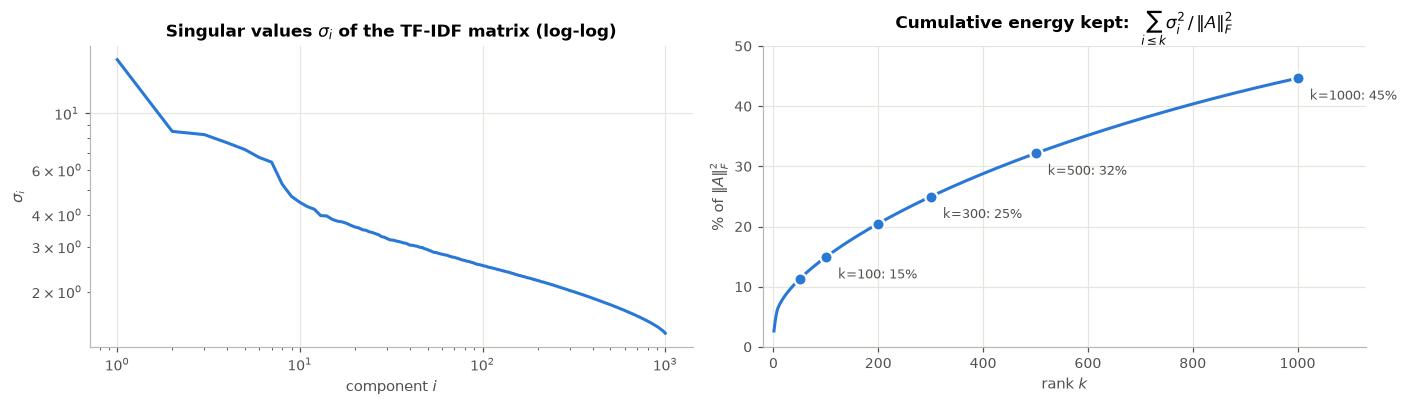

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(np.arange(1, K_MAX + 1), sigma, color=BLUE)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_title("Singular values $\\sigma_i$ of the TF-IDF matrix (log-log)")
ax[0].set_xlabel("component $i$"); ax[0].set_ylabel("$\\sigma_i$")

energy = 100 * np.cumsum(sigma ** 2) / fro2
ax[1].plot(np.arange(1, K_MAX + 1), energy, color=BLUE)
for k in K_VALUES:
    ax[1].plot(k, energy[k - 1], "o", color=BLUE, markeredgecolor="white", markeredgewidth=1.5, markersize=8)
for k in [100, 300, 500, 1000]:                      # label a readable subset; all values are printed in check 5
    ax[1].annotate("k=%d: %.0f%%" % (k, energy[k - 1]), (k, energy[k - 1]), textcoords="offset points",
                   xytext=(8, -14), fontsize=8.5, color="#52514e")
ax[1].set_title("Cumulative energy kept:  $\\sum_{i\\leq k}\\sigma_i^2 \\,/\\, \\|A\\|_F^2$")
ax[1].set_xlabel("rank $k$"); ax[1].set_ylabel("% of $\\|A\\|_F^2$"); ax[1].set_ylim(0, energy[-1] * 1.12); ax[1].set_xlim(-20, 1130)
plt.tight_layout(); plt.show()

In [14]:
for i in range(6):
    v = Vt[i]
    pos = ", ".join(terms[np.argsort(-v)[:8]])
    neg = ", ".join(terms[np.argsort(v)[:8]])
    print("v%d  (sigma = %.2f)" % (i + 1, sigma[i]))
    print("    + : %s" % pos)
    if i > 0:
        print("    - : %s" % neg)

v1  (sigma = 16.23)
    + : learn, machin, comput, machin learn, intellig, process, artifici, artifici intellig
v2  (sigma = 8.50)
    + : softwar, engin, softwar engin, program, softwar develop, manag, cybersecur, develop
    - : learn, machin, machin learn, natur languag, languag process, natur, languag, nlp
v3  (sigma = 8.25)
    + : languag, natur languag, languag process, natur, process, nlp, softwar, process nlp
    - : cybersecur, machin learn, artifici, artifici intellig, intellig, vision, comput vision, learn
v4  (sigma = 7.67)
    + : cybersecur, artifici intellig, intellig, artifici, secur, cyber, threat, risk
    - : vision, comput vision, comput, imag, softwar, engin, softwar engin, learn
v5  (sigma = 7.21)
    + : vision, comput vision, cybersecur, comput, secur, cyber, imag, threat
    - : machin learn, machin, learn, softwar, engin, softwar engin, artifici, artifici intellig
v6  (sigma = 6.71)
    + : artifici intellig, intellig, artifici, vision, comput vision, comput,

In [15]:
def recommend_svd(idx, k_dim=300, k=5):
    '''Top-k papers most similar to paper `idx` in the rank-k_dim SVD space (Approach B).'''
    V_ = Zn[k_dim]
    sims = V_ @ V_[idx]                      # cosine similarity in the latent space
    sims[idx] = -np.inf
    return result_table(sims, top_k(sims, k))

print("QUERY PAPER:", df["title"].iloc[seed], "  (SVD, k = 300)\n")
recommend_svd(seed, 300, 5)

QUERY PAPER: Machine learning and deep learning   (SVD, k = 300)



,similarity,title,domain,year
0,0.525,"Machine learning, artificial intelligence and the prediction of dementia",Machine Learning,2021.0
1,0.522,Machine Learning and Deep Learning Applications-A Vision,Machine Learning,2021.0
2,0.507,Clinical applications of continual learning machine learning,Machine Learning,2020.0
3,0.504,"Trends in artificial intelligence, machine learning, and chemometrics applied to chemi...",Machine Learning,2021.0
4,0.501,"Artificial intelligence, machine learning, and deep learning in women’s health nursing",Machine Learning,2020.0


## 1.4 Tuning the unsupervised models (validation queries only)

Three questions: is the TF-IDF configuration a fair baseline; how does SVD accuracy depend on the rank $k$; does
combining the two (B+) help?

**What the code does** — defines the similarity functions of A, B and B+; evaluates alternative TF-IDF settings;
evaluates every SVD rank; grid-searches the hybrid's $(k, \alpha)$ and keeps the best by validation nDCG@10.

In [16]:
# ---- similarity functions for the unsupervised approaches -----------------------------------------
def sim_tfidf(q):                      # Approach A
    return (A[q] @ A_T).toarray()

def sim_svd(k):                        # Approach B
    V_ = Zn[k]
    return lambda q: V_[q] @ V_.T

def sim_hybrid(k, alpha):              # Approach B+ : alpha * TF-IDF cosine + (1 - alpha) * SVD cosine
    f = sim_svd(k)
    return lambda q: alpha * sim_tfidf(q) + (1 - alpha) * f(q)

In [17]:
# ---- 1. is the baseline configuration reasonable? --------------------------------------------------
variants = {
    "chosen: min_df=5, max_df=0.5, 1-2 grams, sublinear tf": dict(min_df=5, max_df=0.5, ngram_range=(1, 2), sublinear_tf=True),
    "unigrams only":                                         dict(min_df=5, max_df=0.5, ngram_range=(1, 1), sublinear_tf=True),
    "1-3 grams":                                             dict(min_df=5, max_df=0.5, ngram_range=(1, 3), sublinear_tf=True),
    "raw term frequency (no log)":                           dict(min_df=5, max_df=0.5, ngram_range=(1, 2), sublinear_tf=False),
    "min_df=2 (bigger vocabulary)":                          dict(min_df=2, max_df=0.5, ngram_range=(1, 2), sublinear_tf=True),
    "max_df=0.2 (drop more common terms)":                   dict(min_df=5, max_df=0.2, ngram_range=(1, 2), sublinear_tf=True),
}
rows = []
for name, kw in variants.items():
    X = TfidfVectorizer(**kw).fit_transform(df["clean"]).tocsr(); X_T = X.T.tocsr()
    r = summary(evaluate(lambda q: (X[q] @ X_T).toarray(), VAL)); r.update(setting=name, terms=X.shape[1]); rows.append(r)
val_tfidf = pd.DataFrame(rows).set_index("setting")[["terms"] + METRICS]
print("TF-IDF configurations (validation queries)")
display(val_tfidf.round(4))

TF-IDF configurations (validation queries)


,terms,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
setting,,,,,,,,
"chosen: min_df=5, max_df=0.5, 1-2 grams, sublinear tf",31291,0.7365,0.6975,0.0292,0.8604,0.7181,0.7903,0.9710
unigrams only,5726,0.7419,0.7025,0.0294,0.8687,0.7241,0.8050,0.9703
1-3 grams,36564,0.7115,0.6775,0.0276,0.8426,0.6971,0.7660,0.9673
raw term frequency (no log),31291,0.7138,0.6765,0.0278,0.8410,0.6965,0.7700,0.9607
min_df=2 (bigger vocabulary),119792,0.7364,0.6960,0.0298,0.8668,0.7186,0.8000,0.9730
max_df=0.2 (drop more common terms),31254,0.7152,0.6755,0.0293,0.8499,0.6977,0.7733,0.9703


In [18]:
# ---- 2. SVD: quality as a function of k ------------------------------------------------------------
val_scores = {"A: TF-IDF": evaluate(sim_tfidf, VAL)}
for k in K_VALUES:
    val_scores["B: SVD k=%d" % k] = evaluate(sim_svd(k), VAL)

# ---- 3. hybrid: grid over (k, alpha) ---------------------------------------------------------------
grid = []
for k in [300, 500, 1000]:
    for alpha in [0.3, 0.5, 0.7]:
        r = summary(evaluate(sim_hybrid(k, alpha), VAL)); r.update(k=k, alpha=alpha); grid.append(r)
grid = pd.DataFrame(grid)
best = grid.sort_values("nDCG@10", ascending=False).iloc[0]
K_HYB, ALPHA_HYB = int(best["k"]), float(best["alpha"])
val_scores["B+: hybrid"] = evaluate(sim_hybrid(K_HYB, ALPHA_HYB), VAL)

print("Unsupervised approaches (validation queries)")
display(pd.DataFrame({name: summary(s) for name, s in val_scores.items()}).T.round(4))
print("Hybrid grid, validation nDCG@10  (rows: SVD rank k, columns: weight alpha on TF-IDF)")
display(grid.pivot(index="k", columns="alpha", values="nDCG@10").round(4))
print("Chosen hybrid:  k = %d,  alpha = %.1f" % (K_HYB, ALPHA_HYB))

Unsupervised approaches (validation queries)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
A: TF-IDF,0.7365,0.6975,0.0292,0.8604,0.7181,0.7903,0.9710
B: SVD k=50,0.6856,0.6643,0.0172,0.7983,0.6765,0.7270,0.9300
B: SVD k=100,0.7105,0.6861,0.0186,0.8268,0.7009,0.7607,0.9377
B: SVD k=200,0.7345,0.7044,0.0212,0.8461,0.7211,0.7863,0.9463
B: SVD k=300,0.7448,0.7127,0.0238,0.8562,0.7309,0.7980,0.9533
B: SVD k=500,0.7552,0.7214,0.0264,0.8638,0.7397,0.8073,0.9623
B: SVD k=1000,0.7588,0.7188,0.0289,0.8728,0.7401,0.8163,0.9680
B+: hybrid,0.7668,0.7259,0.0280,0.8777,0.7470,0.8227,0.9643


Hybrid grid, validation nDCG@10  (rows: SVD rank k, columns: weight alpha on TF-IDF)


alpha,0.3,0.5,0.7
k,,,
300,0.7394,0.7440,0.7470
500,0.7440,0.7461,0.7437
1000,0.7398,0.7384,0.7344


Chosen hybrid:  k = 300,  alpha = 0.7


## 1.5 Models C and D — supervised machine learning: ridge least squares on the SVD space

SVD keeps the directions of largest *variance*, which is not the same as topical relevance. Model C learns which
combinations of latent directions indicate shared topics.

- **Ridge regression.** With latent vectors $Z \in \mathbb{R}^{m \times 1000}$ and the topic matrix
  $Y \in \{0,1\}^{m \times 1846}$, minimise $\lVert ZW - Y\rVert_F^2 + \lambda\lVert W\rVert_F^2$. The solution of the
  normal equations is $W = (Z^{\mathsf T}Z+\lambda I)^{-1}Z^{\mathsf T}Y$ — one $1000 \times 1000$ linear system.
- **Learned metric.** Scoring two papers by their predicted topic vectors gives $z_q (WW^{\mathsf T}) z_d^{\mathsf T}$,
  a learned inner product. A second SVD, $W = QSP^{\mathsf T}$, truncated to rank $r$, turns it into an
  $r$-dimensional vector $x = zQ_rS_r$ compared by ordinary cosine similarity (reduced-rank regression).
- **Model D** adds exact term matching back: $s_D = (1-\beta)s_C + \beta s_A$.

**What the code does**

- `fit_metric` solves the normal equations and returns $L = QS$; `fit_all_pairs` fits the 15 pair-excluded models
  of §0.5; `make_sim_supervised` returns the leakage-free similarity function; `oof_topic_vectors` is an ordinary
  out-of-fold predictor used for tuning in Part 2 and in the leakage audits.
- Tunes $\lambda$, the latent size and the rank $r$ on the validation queries (parsimony rule: strongest $\lambda$ /
  smallest $r$ whose nDCG@10 is within a small tolerance of the best), plots accuracy against $r$, then tunes $\beta$.

In [19]:
Y = T.toarray().astype(np.float64)                       # (m, 1846) topic incidence matrix = regression targets
has_topic = np.asarray(T.sum(axis=1)).ravel() > 0        # the few papers without topics are never used for training
Z32 = Z.astype(np.float32)

K_FOLDS = 5
fold = np.random.default_rng(SEED).integers(0, K_FOLDS, N)          # fold id of every paper
fold_idx = [np.where(fold == f)[0] for f in range(K_FOLDS)]
pos_in_fold = np.empty(N, dtype=int)                                 # position of each paper inside its fold
for f in range(K_FOLDS):
    pos_in_fold[fold_idx[f]] = np.arange(len(fold_idx[f]))

def fit_metric(train_mask, lam, k_lat=K_MAX, X=None):
    '''Ridge least squares  min ||X W - Y||^2 + lam ||W||^2  on the training papers, followed by an SVD of W.
       X defaults to the first k_lat SVD coordinates (a different feature matrix is used in Part 2).
       Returns L = Q S  (features x min(features, t)); the first r columns give the rank-r learned metric.'''
    X = Z[:, :k_lat] if X is None else X
    Xtr, Ytr = X[train_mask], Y[train_mask]
    G = Xtr.T @ Xtr                                       # Gram matrix Z^T Z            (k x k)
    G[np.diag_indices_from(G)] += lam                     # + lam I   -> symmetric positive definite
    W = sla.solve(G, Xtr.T @ Ytr, assume_a="pos")         # normal equations, solved by Cholesky
    Q, S, _ = np.linalg.svd(W, full_matrices=False)       # second SVD:  W = Q S P^T
    return (Q * S).astype(np.float32)

def fit_all_pairs(lam, k_lat=K_MAX, X=None, keep=None):
    '''One model for every unordered pair of folds (f, g): trained WITHOUT the papers of folds f and g.
       keep = number of leading columns of L to store (None = all).'''
    return {(f, g): fit_metric(has_topic & (fold != f) & (fold != g), lam, k_lat, X)[:, :keep]
            for f in range(K_FOLDS) for g in range(f, K_FOLDS)}

def make_sim_supervised(models, r, k_lat=K_MAX, X=None):
    '''Similarity function for evaluate(): pair-excluded, rank-r learned metric.'''
    X32 = Z32[:, :k_lat] if X is None else X              # float32 feature matrix the models were trained on
    cache = {}
    def reps(key, f):                                     # normalised r-dim vectors of fold f under model `key`
        if (key, f) not in cache:
            cache[(key, f)] = normalize(X32[fold_idx[f]] @ models[key][:, :r])
        return cache[(key, f)]
    def sim(q):
        S = np.empty((len(q), N), dtype=np.float32)
        for f in np.unique(fold[q]):
            rows = np.where(fold[q] == f)[0]              # the queries that belong to fold f
            for g in range(K_FOLDS):                      # candidates in fold g
                key = (min(f, g), max(f, g))              # the model that saw neither fold f nor fold g
                S[np.ix_(rows, fold_idx[g])] = reps(key, f)[pos_in_fold[q[rows]]] @ reps(key, g).T
        return S
    return sim

def oof_topic_vectors(X, lam):
    '''Ordinary out-of-fold prediction: every paper's topic vector x W is produced by a model trained without
       that paper's fold.  Returns unit-length rows (compared in the shared topic space).'''
    P = np.zeros((N, Y.shape[1]), dtype=np.float32)
    for f in range(K_FOLDS):
        tr = has_topic & (fold != f)
        G = X[tr].T @ X[tr]; G[np.diag_indices_from(G)] += lam
        P[fold_idx[f]] = X[fold_idx[f]] @ sla.solve(G, X[tr].T @ Y[tr], assume_a="pos")
    return normalize(P)

print("Fold sizes:", [len(ix) for ix in fold_idx])

Fold sizes: [2015, 1979, 2071, 1958, 1933]


In [20]:
t0 = time.time()
# ---- 1. ridge strength ------------------------------------------------------------------------------
lam_rows, models_by_lam = [], {}
for lam in [0.003, 0.03, 0.3, 3.0, 30.0]:
    models_by_lam[lam] = fit_all_pairs(lam)
    r_ = summary(evaluate(make_sim_supervised(models_by_lam[lam], K_MAX), VAL)); r_.update(lam=lam); lam_rows.append(r_)
lam_tab = pd.DataFrame(lam_rows).set_index("lam")
LAMBDA = float(lam_tab.index[lam_tab["nDCG@10"] >= lam_tab["nDCG@10"].max() - 0.001].max())   # strongest lambda within 0.001 of the best
models = models_by_lam[LAMBDA]; del models_by_lam
print("Ridge strength (k = 1000, full rank), validation queries"); display(lam_tab[METRICS].round(4))
print("Chosen lambda =", LAMBDA)

# ---- 2. how many latent dimensions does the map need? ----------------------------------------------
k_rows = []
for k_lat in [300, 500]:
    mk = fit_all_pairs(LAMBDA, k_lat)
    r_ = summary(evaluate(make_sim_supervised(mk, k_lat, k_lat), VAL)); r_.update(k=k_lat); k_rows.append(r_)
r_ = lam_tab.loc[LAMBDA, METRICS].to_dict(); r_.update(k=K_MAX); k_rows.append(r_)
print("\nLatent dimension k fed into the least-squares map (lambda = %g)" % LAMBDA)
display(pd.DataFrame(k_rows).set_index("k")[METRICS].round(4))

# ---- 3. rank r of the learned metric -----------------------------------------------------------------
R_VALUES = [20, 50, 100, 200, 300, 500, 1000]
rank_tab = pd.DataFrame([dict(summary(evaluate(make_sim_supervised(models, r), VAL)), r=r) for r in R_VALUES]).set_index("r")
print("\nRank r of the learned metric (k = 1000, lambda = %g)" % LAMBDA); display(rank_tab[METRICS].round(4))
R_SUP = int(rank_tab.index[rank_tab["nDCG@10"] >= rank_tab["nDCG@10"].max() - 0.005][0])
print("Chosen rank r = %d      (tuning time: %.0fs)" % (R_SUP, time.time() - t0))

sim_C = make_sim_supervised(models, R_SUP)
val_scores["C: SVD + least squares"] = evaluate(sim_C, VAL)

Ridge strength (k = 1000, full rank), validation queries


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
lam,,,,,,,
0.003,0.8253,0.8096,0.0274,0.8908,0.8199,0.8593,0.9447
0.030,0.8261,0.8092,0.0273,0.8904,0.8197,0.8583,0.9453
0.300,0.8281,0.8079,0.0267,0.8922,0.8193,0.8610,0.9443
3.000,0.8085,0.7900,0.0229,0.8776,0.8007,0.8417,0.9387
30.000,0.7313,0.7108,0.0167,0.8268,0.7230,0.7730,0.9243


Chosen lambda = 0.3



Latent dimension k fed into the least-squares map (lambda = 0.3)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
k,,,,,,,
300,0.7965,0.7766,0.0220,0.8664,0.7872,0.8247,0.9390
500,0.8093,0.7926,0.0239,0.8782,0.8027,0.8400,0.9447
1000,0.8281,0.8079,0.0267,0.8922,0.8193,0.8610,0.9443



Rank r of the learned metric (k = 1000, lambda = 0.3)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
r,,,,,,,
20,0.6881,0.6821,0.0116,0.7568,0.6859,0.6983,0.8623
50,0.7723,0.7586,0.0176,0.8329,0.7652,0.7893,0.9060
100,0.8081,0.7916,0.0225,0.8690,0.8006,0.8340,0.9287
200,0.8260,0.8047,0.0255,0.8876,0.8159,0.8547,0.9417
300,0.8285,0.8066,0.0264,0.8909,0.8183,0.8587,0.9433
500,0.8284,0.8070,0.0266,0.8923,0.8188,0.8610,0.9433
1000,0.8281,0.8079,0.0267,0.8922,0.8193,0.8610,0.9443


Chosen rank r = 200      (tuning time: 18s)


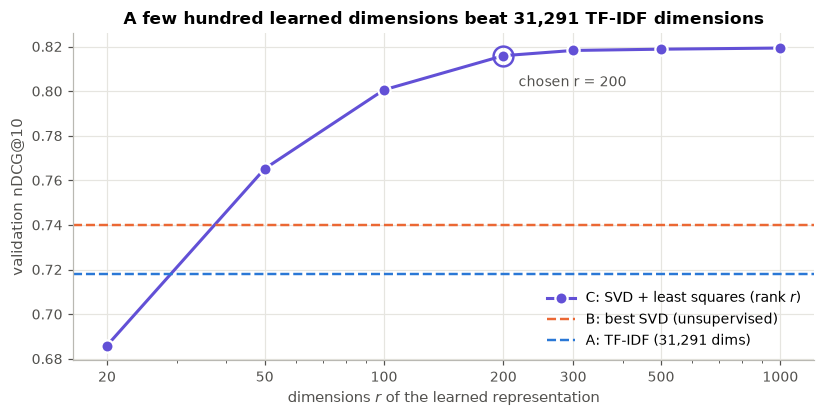

In [21]:
fig, ax = plt.subplots(figsize=(7.6, 3.9))
base_ndcg = val_scores["A: TF-IDF"].mean(axis=0)[4]
svd_ndcg = max(val_scores["B: SVD k=%d" % k].mean(axis=0)[4] for k in K_VALUES)
ax.plot(rank_tab.index, rank_tab["nDCG@10"], "o-", color=VIOLET, markeredgecolor="white", markeredgewidth=1.5,
        markersize=8, label="C: SVD + least squares (rank $r$)")
ax.axhline(svd_ndcg, color=ORANGE, lw=1.6, ls="--", label="B: best SVD (unsupervised)")
ax.axhline(base_ndcg, color=BLUE, lw=1.6, ls="--", label="A: TF-IDF (31,291 dims)")
ax.plot(R_SUP, rank_tab.loc[R_SUP, "nDCG@10"], "o", color=VIOLET, markersize=13, markerfacecolor="none", markeredgewidth=1.6)
ax.annotate("chosen r = %d" % R_SUP, (R_SUP, rank_tab.loc[R_SUP, "nDCG@10"]), textcoords="offset points",
            xytext=(10, -20), fontsize=9, color="#52514e")
ax.set_xscale("log"); ax.set_xticks(R_VALUES); ax.set_xticklabels(R_VALUES)
ax.set_xlabel("dimensions $r$ of the learned representation"); ax.set_ylabel("validation nDCG@10")
ax.set_title("A few hundred learned dimensions beat 31,291 TF-IDF dimensions")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

In [22]:
def sim_fusion(beta):
    return lambda q: (1 - beta) * sim_C(q) + beta * sim_tfidf(q)

fus = pd.DataFrame([dict(summary(evaluate(sim_fusion(b), VAL)), beta=b) for b in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]]).set_index("beta")
BETA = float(fus["nDCG@10"].idxmax())
val_scores["D: fusion of C and A"] = evaluate(sim_fusion(BETA), VAL)
print("Fusion weight beta on TF-IDF (validation queries)"); display(fus[METRICS].round(4))
print("Chosen beta =", BETA)

Fusion weight beta on TF-IDF (validation queries)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
beta,,,,,,,
0.0,0.8260,0.8047,0.0255,0.8876,0.8159,0.8547,0.9417
0.2,0.8282,0.8068,0.0267,0.8927,0.8184,0.8600,0.9450
0.3,0.8289,0.8074,0.0272,0.8949,0.8193,0.8630,0.9490
0.4,0.8286,0.8083,0.0280,0.8973,0.8205,0.8647,0.9510
0.5,0.8298,0.8079,0.0286,0.8987,0.8205,0.8640,0.9553
0.6,0.8287,0.8054,0.0289,0.8997,0.8184,0.8630,0.9583
0.7,0.8243,0.8010,0.0298,0.8978,0.8137,0.8573,0.9620


Chosen beta = 0.4


## 1.6 Accuracy of the machine-learning models (held-out test queries)

All settings are now frozen. The table reports every machine-learning model on the 6,911 test queries.

**What the code does** — registers (evaluates) models A, B at six ranks, B+, C and D, prints the accuracy table with
95% confidence intervals for P@10, and plots SVD accuracy against the rank $k$ with the TF-IDF baseline as reference.

In [23]:
register("A: TF-IDF (baseline)", sim_tfidf, n, "ML")
for k in K_VALUES:
    register("B: SVD k=%d" % k, sim_svd(k), k, "ML")
name_Bp = "B+: hybrid (TF-IDF + SVD k=%d)" % K_HYB
register(name_Bp, sim_hybrid(K_HYB, ALPHA_HYB), n + K_HYB, "ML")
name_C = "C: SVD + least squares (r=%d)" % R_SUP
register(name_C, sim_C, R_SUP, "ML, trained on labels")
name_D = "D: fusion of C and A"
register(name_D, sim_fusion(BETA), n + R_SUP, "ML, trained on labels")
ML_NAMES = list(methods)
base = test_scores["A: TF-IDF (baseline)"]

print("Machine-learning models on %d held-out test queries" % len(TEST))
results_table(ML_NAMES)

Machine-learning models on 6911 held-out test queries


,family,dims,P@1,P@5,P@10,P@10 95% CI,MRR,nDCG@10,Hit@10,R@10
method,,,,,,,,,,
A: TF-IDF (baseline),ML,"31,291",0.7954,0.7380,0.6990,"[0.693, 0.705]",0.8633,0.7198,0.9734,0.0293
B: SVD k=50,ML,50,0.7313,0.6886,0.6679,"[0.660, 0.675]",0.7992,0.6801,0.9200,0.0168
B: SVD k=100,ML,100,0.7558,0.7122,0.6869,"[0.679, 0.694]",0.8213,0.7010,0.9372,0.0192
B: SVD k=200,ML,200,0.7811,0.7313,0.7039,"[0.696, 0.711]",0.8415,0.7196,0.9479,0.0217
B: SVD k=300,ML,300,0.7953,0.7418,0.7115,"[0.704, 0.718]",0.8542,0.7289,0.9562,0.0235
B: SVD k=500,ML,500,0.8074,0.7538,0.7191,"[0.712, 0.726]",0.8640,0.7378,0.9608,0.0263
B: SVD k=1000,ML,"1,000",0.8177,0.7585,0.7206,"[0.714, 0.727]",0.8745,0.7412,0.9670,0.0290
B+: hybrid (TF-IDF + SVD k=300),ML,"31,591",0.8199,0.7637,0.7274,"[0.721, 0.734]",0.8762,0.7472,0.9680,0.0280
C: SVD + least squares (r=200),"ML, trained on labels",200,0.8413,0.8160,0.7992,"[0.792, 0.806]",0.8778,0.8085,0.9400,0.0258


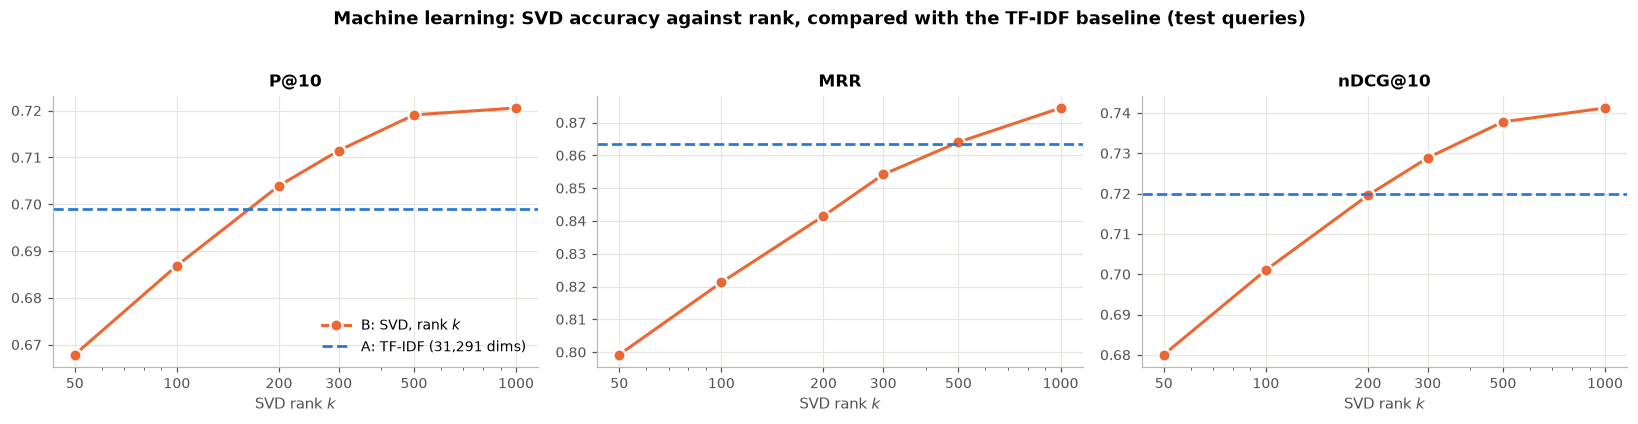

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.7), sharex=True)
for a, mname in zip(ax, ["P@10", "MRR", "nDCG@10"]):
    mi = COL[mname]
    ys = [test_scores["B: SVD k=%d" % k][:, mi].mean() for k in K_VALUES]
    a.plot(K_VALUES, ys, "o-", color=ORANGE, markeredgecolor="white", markeredgewidth=1.5, markersize=8, label="B: SVD, rank $k$")
    a.axhline(base[:, mi].mean(), color=BLUE, lw=1.8, ls="--", label="A: TF-IDF (31,291 dims)")
    a.set_xscale("log"); a.set_xticks(K_VALUES); a.set_xticklabels(K_VALUES)
    a.set_title(mname); a.set_xlabel("SVD rank $k$")
ax[0].legend(loc="lower right")
fig.suptitle("Machine learning: SVD accuracy against rank, compared with the TF-IDF baseline (test queries)",
             y=1.03, fontsize=11.5, fontweight="bold")
plt.tight_layout(); plt.show()

### Leakage audit for the supervised machine-learning model

Model C is evaluated under three protocols. If the reported protocol leaked label information, its score would be
close to the in-sample one.

**What the code does** — trains one map on all labelled papers (`L_all`; also the deployment model used later for
timing and search) and scores it in-sample; scores ordinary out-of-fold predictions; compares both with the
reported pairwise-exclusion score.

In [25]:
t0 = time.time()
L_all = fit_metric(has_topic, LAMBDA)[:, :R_SUP]            # one map trained on ALL labelled papers
R_all = normalize(Z32 @ L_all)                               # every paper as a unit r-vector
sup_fit_time = time.time() - t0
s_insample = evaluate(lambda q: R_all[q] @ R_all.T, TEST)
P_oof = oof_topic_vectors(Z, LAMBDA)
s_oof = evaluate(lambda q: P_oof[q] @ P_oof.T, TEST)
del P_oof
audit_C = pd.DataFrame({"in-sample (INVALID: the model saw both papers' labels)": summary(s_insample),
                        "ordinary out-of-fold (full rank)": summary(s_oof),
                        "pairwise exclusion, r=%d (REPORTED)" % R_SUP: summary(test_scores[name_C])}).T
audit_C[["P@1", "P@10", "MRR", "nDCG@10", "Hit@10"]].round(4)

,P@1,P@10,MRR,nDCG@10,Hit@10
in-sample (INVALID: the model saw both papers' labels),0.9045,0.8682,0.9264,0.8765,0.9628
ordinary out-of-fold (full rank),0.8443,0.8033,0.8794,0.8122,0.9417
"pairwise exclusion, r=200 (REPORTED)",0.8413,0.7992,0.8778,0.8085,0.9400


## 1.7 Analysis of the machine-learning results

**Accuracy.**

| Model | Dimensions | P@1 | P@10 | MRR | Hit@10 |
|---|---:|---:|---:|---:|---:|
| A — TF-IDF | 31,291 | 0.795 | 0.699 | 0.863 | 0.973 |
| B — SVD, $k=300$ | 300 | 0.795 | 0.712 | 0.854 | 0.956 |
| B — SVD, $k=1000$ | 1,000 | 0.818 | 0.721 | 0.875 | 0.967 |
| B+ — hybrid | 31,591 | 0.820 | 0.727 | 0.876 | 0.968 |
| C — SVD + least squares | 200 | 0.841 | 0.799 | 0.878 | 0.940 |
| **D — fusion of C and A** | 31,491 | **0.855** | **0.801** | **0.891** | 0.954 |

1. **The baseline is already strong.** TF-IDF with cosine similarity puts a relevant paper first 79.5% of the time
   and 7 of its 10 recommendations are relevant — nine times better than chance (0.075).
2. **SVD trades a little information for a lot of compression.** Ranks 50 and 100 lose accuracy. Rank 200 matches
   the baseline on Precision@10 (0.704 against 0.699, overlapping confidence intervals) with 156× fewer dimensions.
   From rank 300 SVD is better on precision, and at rank 1000 also on P@1 and MRR. The gain is real but small — about
   two points — because SVD is unsupervised: it keeps the directions of largest variance, not necessarily the
   directions that separate topics.
3. **The hybrid B+ beats both of its parts** (0.727): exact word matching (TF-IDF) and concept matching (SVD) make
   different mistakes.
4. **Supervision is what moves the needle.** The ridge least-squares map (model C) raises Precision@10 from 0.727 to
   **0.799** with only **200 dimensions**. It works because the map re-weights the latent directions by how useful
   they are for predicting topics.
5. **A cost of supervision.** Model C lowers Hit@10 from 0.973 to 0.940: it concentrates on the dominant topics, so
   it returns more relevant papers on average but misses completely slightly more often. Fusing it with TF-IDF
   (model D) recovers part of that and gives the best machine-learning model: **P@10 0.801, P@1 0.855, MRR 0.891.**

**Is the supervised result honest?** The leakage audit shows Precision@10 = 0.868 when the model has seen the labels
of the papers it scores, 0.803 with ordinary out-of-fold prediction and 0.799 with the reported pairwise exclusion.
The reported figure is seven points below the leaky one and equal to the out-of-fold one — it is generalisation, not
memorisation.

**Strengths of the machine-learning family.** Closed-form solutions (one SVD, one $1000 \times 1000$ linear system);
about 15 seconds to build everything on a laptop CPU; no external models or data; every step can be inspected —
the SVD directions are readable lists of words, and each identity used was verified numerically.

**Weaknesses.** It only sees *which stems occur*. Word order, context and words that never co-occur in this corpus
are invisible, and its accuracy saturates around 0.80 even with labels.

---
# Part 2 — Deep learning

## 2.1 The algorithm: pretrained transformer encoders

A **transformer encoder** is a deep neural network that turns a passage of text into one dense vector:

1. **Sub-word tokenisation** — the raw text (no stemming, no stop-word removal) is split into word pieces.
2. **Embedding + positions** — each token gets a vector plus a position signal, so word order is preserved.
3. **Stacked self-attention layers** — in every layer each token's vector is updated with a weighted mixture of all
   other tokens' vectors (the attention weights are computed from the vectors themselves), followed by a small
   feed-forward network. After 6–12 layers each token vector reflects its whole context.
4. **Pooling** — the token vectors are reduced to one vector (their mean, or the special `[CLS]` token).
5. **Normalisation** — the vector is scaled to unit length, so cosine similarity is a dot product, exactly as in Part 1.

The networks are **pretrained** by their authors with *contrastive learning*: on hundreds of millions of text
pairs known to be related, the weights are adjusted so that related texts get nearby vectors and unrelated texts
distant ones. We use three published encoders as fixed feature extractors — **no transformer is trained in this
notebook**, and none of them was trained on this corpus's topic labels.

| Code | Model | Layers | Parameters | Output | Pooling | Pretraining data |
|---|---|---:|---:|---:|---|---|
| E1 | `sentence-transformers/all-MiniLM-L6-v2` | 6 | ≈ 23 M | 384 | mean | > 1 billion general sentence pairs |
| E2 | `sentence-transformers/allenai-specter` | 12 | ≈ 110 M | 768 | `[CLS]` | scientific papers (title + abstract); citation links as the training signal |
| E3 | `BAAI/bge-base-en-v1.5` | 12 | ≈ 109 M | 768 | `[CLS]` | large-scale general retrieval pairs |

### The deep-learning models evaluated

- **E1, E2, E3** — one encoder each; recommend by cosine similarity of its embeddings. No labels.
- **E** — the three unit embeddings concatenated and divided by $\sqrt3$; the dot product is the mean of the three
  cosine similarities (an ensemble). No labels.
- **F−** — the supervised head of Part 1 (ridge least squares → SVD of the map) applied to the embeddings.
- **F** — the same head applied to [embeddings, SVD vector of Part 1]: deep and classical features together.
- **G** — fusion $s_G = (1-w)\,s_F + w\,s_E$.

## 2.2 Computing (or loading) the embeddings

Encoding 9,956 abstracts with three transformers takes about 4.5 minutes on a laptop GPU and needs the optional
packages `torch` and `sentence-transformers` plus a one-off download of ≈1 GB of model weights. The embeddings are
therefore cached in `data/paper_embeddings.npz` (35 MB); the cell **loads the cache if present and recomputes it
otherwise**, so the notebook runs with or without PyTorch.

**What the code does** — `get_encoder` / `encode` load an encoder on first use and embed texts; the cache is loaded
and checked row by row against the corpus; `E_cat` (model E) is built; each encoder and the ensemble are scored on
the validation queries next to the two best unsupervised machine-learning models.

In [26]:
EMB_MODELS = {                       # key: (Hugging Face model name, maximum number of tokens read)
    "minilm":  ("sentence-transformers/all-MiniLM-L6-v2", 256),
    "specter": ("sentence-transformers/allenai-specter",   384),
    "bge":     ("BAAI/bge-base-en-v1.5",                   384),
}
EMB_PATH = os.path.join(os.path.dirname(DATA_PATH), "paper_embeddings.npz")
_encoders = {}

def get_encoder(key):
    '''Load a pretrained encoder on first use (needs the optional packages torch and sentence-transformers).'''
    if key not in _encoders:
        import logging
        os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
        os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
        logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
        import torch, transformers
        from sentence_transformers import SentenceTransformer
        transformers.utils.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
        name, max_len = EMB_MODELS[key]
        device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
        try:                                                   # use the local model cache if the weights are there
            enc = SentenceTransformer(name, device=device, local_files_only=True)
        except Exception:                                      # first use: download the weights
            enc = SentenceTransformer(name, device=device)
        enc.max_seq_length = max_len
        _encoders[key] = enc
    return _encoders[key]

def encode(key, texts):
    '''texts -> unit-length embedding vectors, one row per text.'''
    out = get_encoder(key).encode(list(texts), batch_size=32, convert_to_numpy=True,
                                  normalize_embeddings=True, show_progress_bar=False)
    return out.astype(np.float32)

def paper_texts(key):
    sep = " [SEP] " if key == "specter" else ". "          # SPECTER was trained on "title [SEP] abstract"
    return (df["title"].fillna("") + sep + df["abstract"].fillna("")).tolist()

paper_ids = df["paper_id"].to_numpy(dtype=str)
if os.path.exists(EMB_PATH):
    cache = np.load(EMB_PATH, allow_pickle=False)
    assert (cache["paper_id"] == paper_ids).all(), "embedding cache does not match the corpus rows"
    print("Loaded cached embeddings:", EMB_PATH)
else:
    t0 = time.time()
    cache = {k: encode(k, paper_texts(k)).astype(np.float16) for k in EMB_MODELS}
    np.savez_compressed(EMB_PATH, paper_id=paper_ids, **cache)
    print("Computed and cached embeddings in %.0fs: %s" % (time.time() - t0, EMB_PATH))

EMB = {k: normalize(cache[k].astype(np.float32)) for k in EMB_MODELS}        # unit rows
E_cat = np.hstack([EMB[k] for k in EMB_MODELS]) / np.sqrt(len(EMB_MODELS))   # unit rows; dot = mean of 3 cosines
print("Embedding shapes:", {k: v.shape for k, v in EMB.items()}, " combined:", E_cat.shape)

def sim_E(q):                          # Approach E
    return E_cat[q] @ E_cat.T

rows = {"A: TF-IDF (for reference)": summary(val_scores["A: TF-IDF"]),
        "B+: hybrid (for reference)": summary(val_scores["B+: hybrid"])}
for k_ in EMB_MODELS:
    rows["%s alone" % k_] = summary(evaluate(lambda q: EMB[k_][q] @ EMB[k_].T, VAL))
val_scores["E: transformer embeddings"] = evaluate(sim_E, VAL)
rows["E: all three combined"] = summary(val_scores["E: transformer embeddings"])
print("Pretrained embeddings, no labels (validation queries)")
pd.DataFrame(rows).T[METRICS].round(4)

Loaded cached embeddings: ../data/paper_embeddings.npz
Embedding shapes: {'minilm': (9956, 384), 'specter': (9956, 768), 'bge': (9956, 768)}  combined: (9956, 1920)


Pretrained embeddings, no labels (validation queries)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
A: TF-IDF (for reference),0.7365,0.6975,0.0292,0.8604,0.7181,0.7903,0.9710
B+: hybrid (for reference),0.7668,0.7259,0.0280,0.8777,0.7470,0.8227,0.9643
minilm alone,0.8636,0.8311,0.0350,0.9430,0.8491,0.9130,0.9893
specter alone,0.8489,0.8198,0.0334,0.9282,0.8363,0.8957,0.9820
bge alone,0.8716,0.8375,0.0366,0.9433,0.8555,0.9147,0.9900
E: all three combined,0.8872,0.8555,0.0381,0.9535,0.8720,0.9293,0.9910


## 2.3 Adding the supervised head: models F−, F and G

The pretrained embeddings know language in general; the supervised head teaches them what "related" means *for this
corpus*. It is the same algorithm as model C — ridge least squares to topic space, SVD of the learned map, cosine
in the resulting low-dimensional space — with the same pairwise-exclusion protocol.

**What the code does**

- `features_F(s)` builds the 2,920-dimensional feature matrix [3 embeddings scaled by $s$, 1000-d SVD vector].
- Tunes $s$ and $\lambda$ on the validation queries (ordinary out-of-fold prediction is used as a fast selection
  device; the reported numbers always use pairwise exclusion), fits the 15 pair-excluded models, and chooses the
  rank $r$ by the parsimony rule.
- Fits **F−** with the same settings but *without* the SVD block (1,920 features) — an ablation that isolates what
  the deep features achieve by themselves.
- Tunes the fusion weight $w$ of model G.

In [27]:
def features_F(s):
    '''[ s * embedding_1, s * embedding_2, s * embedding_3, SVD latent vector ]  ->  (m, 2920)'''
    return np.hstack([s * EMB[k] for k in EMB_MODELS] + [Z]).astype(np.float64)

t0 = time.time()
def tune_F(s_, lam):
    P_ = oof_topic_vectors(features_F(s_), lam)
    return dict(summary(evaluate(lambda q: P_[q] @ P_.T, VAL)), s=s_, lam=lam)

tune = [tune_F(s_, 1.0) for s_ in [1.0, 2.0, 4.0]]                           # 1. embedding scale s
S_F = float(max(tune, key=lambda r_: r_["nDCG@10"])["s"])
tune += [tune_F(S_F, lam) for lam in [0.3, 3.0, 10.0]]                             # 2. ridge strength lambda
tune = pd.DataFrame(tune).set_index(["s", "lam"])
LAMBDA_F = float(tune.loc[S_F, "nDCG@10"].idxmax())
print("Tuning by ordinary out-of-fold prediction (validation queries)"); display(tune[METRICS].round(4))
print("Chosen: s = %g, lambda = %g" % (S_F, LAMBDA_F))

X_F = features_F(S_F); X_F32 = X_F.astype(np.float32)
models_F = fit_all_pairs(LAMBDA_F, X=X_F, keep=1000)                         # the 15 pair-excluded models
rankF = pd.DataFrame([dict(summary(evaluate(make_sim_supervised(models_F, r, X=X_F32), VAL)), r=r)
                      for r in [50, 100, 200, 300, 500, 1000]]).set_index("r")
print("\nRank r of the learned metric, pairwise exclusion (validation queries)"); display(rankF[METRICS].round(4))
R_F = int(rankF.index[rankF["nDCG@10"] >= rankF["nDCG@10"].max() - 0.005][0])
print("Chosen rank r = %d      (tuning + fitting time: %.0fs)" % (R_F, time.time() - t0))

sim_F = make_sim_supervised(models_F, R_F, X=X_F32)
val_scores["F: embeddings + SVD + least squares"] = evaluate(sim_F, VAL)

Tuning by ordinary out-of-fold prediction (validation queries)


P@5    P@10    R@10     MRR  nDCG@10     P@1  Hit@10
s   lam                                                          
1.0 1.0   0.8989  0.8836  0.0358  0.9430   0.8926  0.9237  0.9760
2.0 1.0   0.9023  0.8856  0.0361  0.9435   0.8947  0.9253  0.9747
4.0 1.0   0.9012  0.8840  0.0364  0.9428   0.8936  0.9260  0.9743
2.0 0.3   0.8981  0.8825  0.0355  0.9389   0.8910  0.9203  0.9707
    3.0   0.9019  0.8857  0.0364  0.9450   0.8950  0.9267  0.9783
    10.0  0.9003  0.8791  0.0359  0.9500   0.8909  0.9330  0.9783

Chosen: s = 2, lambda = 3



Rank r of the learned metric, pairwise exclusion (validation queries)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
r,,,,,,,
50,0.8216,0.8088,0.0210,0.8842,0.8173,0.8547,0.9410
100,0.8674,0.8516,0.0277,0.9249,0.8618,0.9010,0.9670
200,0.8924,0.8735,0.0331,0.9407,0.8840,0.9183,0.9763
300,0.8979,0.8794,0.0352,0.9453,0.8898,0.9240,0.9797
500,0.9012,0.8815,0.0365,0.9471,0.8923,0.9263,0.9787
1000,0.9030,0.8828,0.0370,0.9492,0.8939,0.9300,0.9793


Chosen rank r = 300      (tuning + fitting time: 29s)


In [28]:
# ---- F-: the same supervised head on the embeddings ONLY (no SVD features) ----------------------------
t0 = time.time()
X_E = np.hstack([S_F * EMB[k_] for k_ in EMB_MODELS]).astype(np.float64)
X_E32 = X_E.astype(np.float32)
models_Fm = fit_all_pairs(LAMBDA_F, X=X_E, keep=R_F)                 # 15 pair-excluded models, 1,920 features
sim_Fm = make_sim_supervised(models_Fm, R_F, X=X_E32)
val_scores["F-: embeddings + least squares"] = evaluate(sim_Fm, VAL)
print("F- fitted in %.0fs.  Validation:" % (time.time() - t0),
      {k_: round(v_, 4) for k_, v_ in summary(val_scores["F-: embeddings + least squares"]).items() if k_ in ("P@10", "MRR", "nDCG@10")})

F- fitted in 8s.  Validation: {'P@10': np.float64(0.8743), 'MRR': np.float64(0.9471), 'nDCG@10': np.float64(0.8866)}


In [29]:
def sim_G(w):
    return lambda q: (1 - w) * sim_F(q) + w * sim_E(q)

fusG = pd.DataFrame([dict(summary(evaluate(sim_G(w), VAL)), w=w) for w in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6]]).set_index("w")
W_G = float(fusG["nDCG@10"].idxmax())
val_scores["G: fusion of F and E"] = evaluate(sim_G(W_G), VAL)
print("Fusion weight w on the raw embeddings (validation queries)"); display(fusG[METRICS].round(4))
print("Chosen w =", W_G)

Fusion weight w on the raw embeddings (validation queries)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
w,,,,,,,
0.0,0.8979,0.8794,0.0352,0.9453,0.8898,0.9240,0.9797
0.2,0.9020,0.8818,0.0361,0.9499,0.8931,0.9303,0.9807
0.3,0.9021,0.8834,0.0368,0.9519,0.8946,0.9327,0.9827
0.4,0.9037,0.8841,0.0374,0.9541,0.8957,0.9357,0.9847
0.5,0.9043,0.8837,0.0379,0.9553,0.8956,0.9370,0.9857
0.6,0.9054,0.8830,0.0385,0.9563,0.8954,0.9373,0.9880


Chosen w = 0.4


## 2.4 Accuracy of the deep-learning models (held-out test queries)

**What the code does** — registers (evaluates) E1–E3, E, F−, F and G on the 6,911 test queries and prints the
accuracy table with 95% confidence intervals for P@10.

In [30]:
for key_, label_ in [("minilm", "E1: MiniLM-L6 alone"), ("specter", "E2: SPECTER alone"), ("bge", "E3: BGE-base alone")]:
    register(label_, (lambda M_: (lambda q: M_[q] @ M_.T))(EMB[key_]), EMB[key_].shape[1], "DL")
name_E = "E: transformer embeddings (unsupervised)"
register(name_E, sim_E, E_cat.shape[1], "DL")
name_Fm = "F-: embeddings + least squares (r=%d)" % R_F
register(name_Fm, sim_Fm, R_F, "DL, trained on labels")
name_F = "F: embeddings + SVD + least squares (r=%d)" % R_F
register(name_F, sim_F, R_F, "DL + ML, trained on labels")
name_G = "G: fusion of F and E"
register(name_G, sim_G(W_G), R_F + E_cat.shape[1], "DL + ML, trained on labels")
DL_NAMES = [m_ for m_ in methods if m_ not in ML_NAMES]

print("Deep-learning models on %d held-out test queries" % len(TEST))
results_table(DL_NAMES)

Deep-learning models on 6911 held-out test queries


,family,dims,P@1,P@5,P@10,P@10 95% CI,MRR,nDCG@10,Hit@10,R@10
method,,,,,,,,,,
E1: MiniLM-L6 alone,DL,384,0.9023,0.8627,0.8313,"[0.825, 0.837]",0.9343,0.8477,0.9860,0.0359
E2: SPECTER alone,DL,768,0.8963,0.8513,0.8188,"[0.813, 0.825]",0.9291,0.8361,0.9816,0.0344
E3: BGE-base alone,DL,768,0.9152,0.8703,0.8374,"[0.832, 0.843]",0.9433,0.8550,0.9881,0.0374
E: transformer embeddings (unsupervised),DL,"1,920",0.9227,0.8822,0.8523,"[0.847, 0.858]",0.9479,0.8685,0.9878,0.0386
F-: embeddings + least squares (r=300),"DL, trained on labels",300,0.9201,0.8908,0.8720,"[0.866, 0.878]",0.9404,0.8830,0.9761,0.0362
F: embeddings + SVD + least squares (r=300),"DL + ML, trained on labels",300,0.9224,0.8943,0.8741,"[0.868, 0.880]",0.9420,0.8853,0.9745,0.0357
G: fusion of F and E,"DL + ML, trained on labels","2,220",0.9292,0.9017,0.8806,"[0.875, 0.886]",0.9484,0.8919,0.9816,0.0380


### Leakage audit for the supervised deep-learning models

**What the code does** — the same three protocols as in Part 1, for model F: in-sample (invalid), ordinary
out-of-fold, and the reported pairwise exclusion. `L_F_all` / `R_F_all` are the deployment model used later.

In [31]:
t0 = time.time()
L_F_all = fit_metric(has_topic, LAMBDA_F, X=X_F)[:, :R_F]
R_F_all = normalize(X_F32 @ L_F_all)
supF_fit_time = time.time() - t0
sF_insample = evaluate(lambda q: R_F_all[q] @ R_F_all.T, TEST)
P_oof = oof_topic_vectors(X_F, LAMBDA_F)
sF_oof = evaluate(lambda q: P_oof[q] @ P_oof.T, TEST)
del P_oof
audit_F = pd.DataFrame({"in-sample (INVALID: the model saw both papers' labels)": summary(sF_insample),
                        "ordinary out-of-fold (full rank)": summary(sF_oof),
                        "pairwise exclusion, r=%d (REPORTED)" % R_F: summary(test_scores[name_F])}).T
audit_F[["P@1", "P@10", "MRR", "nDCG@10", "Hit@10"]].round(4)

,P@1,P@10,MRR,nDCG@10,Hit@10
in-sample (INVALID: the model saw both papers' labels),0.9683,0.9429,0.9749,0.9492,0.9873
ordinary out-of-fold (full rank),0.9195,0.8804,0.9397,0.8898,0.9745
"pairwise exclusion, r=300 (REPORTED)",0.9224,0.8741,0.9420,0.8853,0.9745


### What limits the accuracy?

Two diagnostics on the test set:

1. For every pair of labelled papers, bucketed by text similarity: what fraction shares a topic? (If even very
   similar papers often share no topic, the labels are noisy.)
2. Test queries grouped by how close their 10th nearest neighbour is — a measure of how densely the corpus covers
   the query's subject — with Precision@10 of the baseline, model E and model G in each group.

**What the code does** — `agreement_by_similarity` walks through all pairs once and tabulates topic agreement per
similarity bucket for TF-IDF and for the embeddings; the second table computes the 10th-neighbour similarity of
each test query and averages P@10 per group.

In [32]:
def agreement_by_similarity(sim_fn, edges):
    '''For all labelled pairs (i < j): number of pairs and fraction sharing a topic, per similarity bucket.'''
    cnt = np.zeros(len(edges) - 1); agree = np.zeros(len(edges) - 1)
    cols = np.arange(N)
    for s0 in range(0, N, 500):
        q = np.arange(s0, min(N, s0 + 500))
        Sm = np.asarray(sim_fn(q))
        valid = has_topic[q][:, None] & has_topic[None, :] & (q[:, None] < cols[None, :])
        b = np.digitize(Sm, edges) - 1
        for i in range(len(edges) - 1):
            mk = valid & (b == i)
            cnt[i] += mk.sum(); agree[i] += REL[q][mk].sum()
    return cnt.astype(int), agree / np.maximum(cnt, 1)

edges = [0.5, 0.6, 0.7, 0.8, 0.9, 1.01]
labels = ["0.5-0.6", "0.6-0.7", "0.7-0.8", "0.8-0.9", "0.9-1.0"]
c1, a1 = agreement_by_similarity(sim_tfidf, edges)
c2, a2 = agreement_by_similarity(sim_E, edges)
ceiling = pd.DataFrame({("TF-IDF cosine", "pairs"): c1, ("TF-IDF cosine", "share a topic"): a1,
                        ("embedding cosine (E)", "pairs"): c2, ("embedding cosine (E)", "share a topic"): a2},
                       index=pd.Index(labels, name="text similarity of the pair"))
display(ceiling.style.format({c_: "{:.3f}" for c_ in ceiling.columns if c_[1] == "share a topic"}))

# ---- per query: how close are the 10 nearest neighbours, and how precise is the best system there? -------
kth = np.concatenate([np.sort(np.where(np.arange(N)[None, :] == q[:, None], -1.0, sim_E(q)), axis=1)[:, -10]
                      for q in np.array_split(TEST, 14)])              # embedding cosine of the 10th nearest neighbour
bins = [-1, 0.6, 0.7, 0.8, 1.01]; names_ = ["below 0.6", "0.6-0.7", "0.7-0.8", "0.8 or more"]
grp = np.digitize(kth, bins) - 1
by_density = pd.DataFrame({"share of test queries": [np.mean(grp == i) for i in range(4)],
                           "A: TF-IDF  P@10": [test_scores["A: TF-IDF (baseline)"][grp == i, 1].mean() for i in range(4)],
                           "E: embeddings  P@10": [test_scores["E: transformer embeddings (unsupervised)"][grp == i, 1].mean() for i in range(4)],
                           "G: best system  P@10": [test_scores["G: fusion of F and E"][grp == i, 1].mean() for i in range(4)]},
                          index=pd.Index(names_, name="embedding cosine of the query's 10th nearest neighbour"))
by_density.round(3)

,share of test queries,A: TF-IDF P@10,E: embeddings P@10,G: best system P@10
embedding cosine of the query's 10th nearest neighbour,,,,
below 0.6,0.004,0.272,0.417,0.407
0.6-0.7,0.145,0.464,0.648,0.682
0.7-0.8,0.629,0.691,0.858,0.892
0.8 or more,0.222,0.884,0.978,0.987


## 2.5 Analysis of the deep-learning results

**Accuracy.**

| Model | Dimensions | Labels used | P@1 | P@10 | MRR | Hit@10 |
|---|---:|---|---:|---:|---:|---:|
| E1 — MiniLM-L6 alone | 384 | no | 0.902 | 0.831 | 0.934 | 0.986 |
| E2 — SPECTER alone | 768 | no | 0.896 | 0.819 | 0.929 | 0.982 |
| E3 — BGE-base alone | 768 | no | 0.915 | 0.837 | 0.943 | 0.988 |
| E — the three combined | 1,920 | no | 0.923 | 0.852 | 0.948 | **0.988** |
| F− — embeddings + least squares | 300 | yes | 0.920 | 0.872 | 0.940 | 0.976 |
| F — embeddings + SVD + least squares | 300 | yes | 0.922 | 0.874 | 0.942 | 0.975 |
| **G — fusion of F and E** | 2,220 | yes | **0.929** | **0.881** | **0.948** | 0.982 |

1. **A single pretrained encoder, with no training at all, beats every machine-learning model of Part 1.** Even the
   smallest network (MiniLM, 23 M parameters, 384 dimensions) scores Precision@10 = 0.831, against 0.801 for the
   best label-trained machine-learning model. The encoders already know from pretraining that, for example,
   *"intrusion detection"* and *"network attack classification"* belong together.
2. **A bigger or more specialised network is not automatically better.** BGE-base is the best single encoder;
   SPECTER, although trained specifically on scientific papers, is the weakest of the three here, and the 6-layer
   MiniLM is within one point of the 12-layer BGE.
3. **Ensembling helps.** Averaging the three similarity scores (model E) adds 1.5 points over the best single
   encoder: the networks were trained on different data and make different mistakes.
4. **The supervised head adds two points** (0.852 → 0.872) and compresses 1,920 dimensions into 300. The gain is
   much smaller than in Part 1 (where the same head added seven points), because pretrained embeddings already
   contain most of the topical structure that the head had to learn from scratch for bag-of-words features.
5. **The same cost of supervision appears.** The head lowers Hit@10 (0.988 → 0.976) and MRR (0.948 → 0.940);
   fusing with the raw embeddings (model G) restores them and gives the best model of the notebook:
   **P@10 0.881, P@1 0.929, MRR 0.948, Hit@10 0.982.**

**Is the supervised result honest?** Same audit as in Part 1: 0.943 in-sample (invalid), 0.880 out-of-fold, 0.874
reported. Note that the *only* configuration in this notebook that reaches about 0.95 is the invalid in-sample one —
a 95% figure would be over-fitting.

**What limits the accuracy.** Pairs of papers whose embeddings are very close (cosine ≥ 0.8) share a topic 97–99% of
the time, but at cosine 0.7–0.8 only 83% do, and at 0.6–0.7 only 49%. A query can only receive ten good
recommendations if the corpus *contains* ten close papers: for the 22% of test queries whose 10th nearest neighbour
is at cosine ≥ 0.8, model G reaches Precision@10 = **0.987**; for the 63% in the 0.7–0.8 band it reaches 0.892; for
the 15% whose neighbourhood is sparse it drops to about 0.68. The ceiling is set by the coverage of a
10,000-paper corpus and the coarseness of an automatic topic label, not by the model.

**Strengths of the deep-learning family.** Understands meaning, paraphrase and word order; excellent without any
labels; needs no preprocessing rules.

**Weaknesses.** The networks are black boxes with 23–110 million parameters; they depend on external pretrained
weights (≈1 GB) and the PyTorch stack; encoding the corpus takes minutes on a GPU instead of seconds on a CPU; the
raw embedding index is 13× larger than the TF-IDF matrix; and because the encoders were pretrained on very large
public text collections, they may have seen some of these abstracts as plain text (never their topic labels).

---
# Part 3 — Comparative analysis: machine learning vs deep learning

## 3.1 Accuracy side by side

**What the code does** — prints one table with every model of Parts 1 and 2 on the same test queries, and plots
the main models with 95% confidence intervals (blue = machine learning, orange = deep learning; the dotted line is
the TF-IDF baseline).

In [33]:
p_rand = N_REL[TEST] / (N - 1)
print("Reference - random ranking: P@1 = P@5 = P@10 = %.3f,  Hit@10 = %.3f" % (p_rand.mean(), (1 - (1 - p_rand) ** 10).mean()))
results_table(ML_NAMES + DL_NAMES)

Reference - random ranking: P@1 = P@5 = P@10 = 0.075,  Hit@10 = 0.481


,family,dims,P@1,P@5,P@10,P@10 95% CI,MRR,nDCG@10,Hit@10,R@10
method,,,,,,,,,,
A: TF-IDF (baseline),ML,"31,291",0.7954,0.7380,0.6990,"[0.693, 0.705]",0.8633,0.7198,0.9734,0.0293
B: SVD k=50,ML,50,0.7313,0.6886,0.6679,"[0.660, 0.675]",0.7992,0.6801,0.9200,0.0168
B: SVD k=100,ML,100,0.7558,0.7122,0.6869,"[0.679, 0.694]",0.8213,0.7010,0.9372,0.0192
B: SVD k=200,ML,200,0.7811,0.7313,0.7039,"[0.696, 0.711]",0.8415,0.7196,0.9479,0.0217
B: SVD k=300,ML,300,0.7953,0.7418,0.7115,"[0.704, 0.718]",0.8542,0.7289,0.9562,0.0235
B: SVD k=500,ML,500,0.8074,0.7538,0.7191,"[0.712, 0.726]",0.8640,0.7378,0.9608,0.0263
B: SVD k=1000,ML,"1,000",0.8177,0.7585,0.7206,"[0.714, 0.727]",0.8745,0.7412,0.9670,0.0290
B+: hybrid (TF-IDF + SVD k=300),ML,"31,591",0.8199,0.7637,0.7274,"[0.721, 0.734]",0.8762,0.7472,0.9680,0.0280
C: SVD + least squares (r=200),"ML, trained on labels",200,0.8413,0.8160,0.7992,"[0.792, 0.806]",0.8778,0.8085,0.9400,0.0258


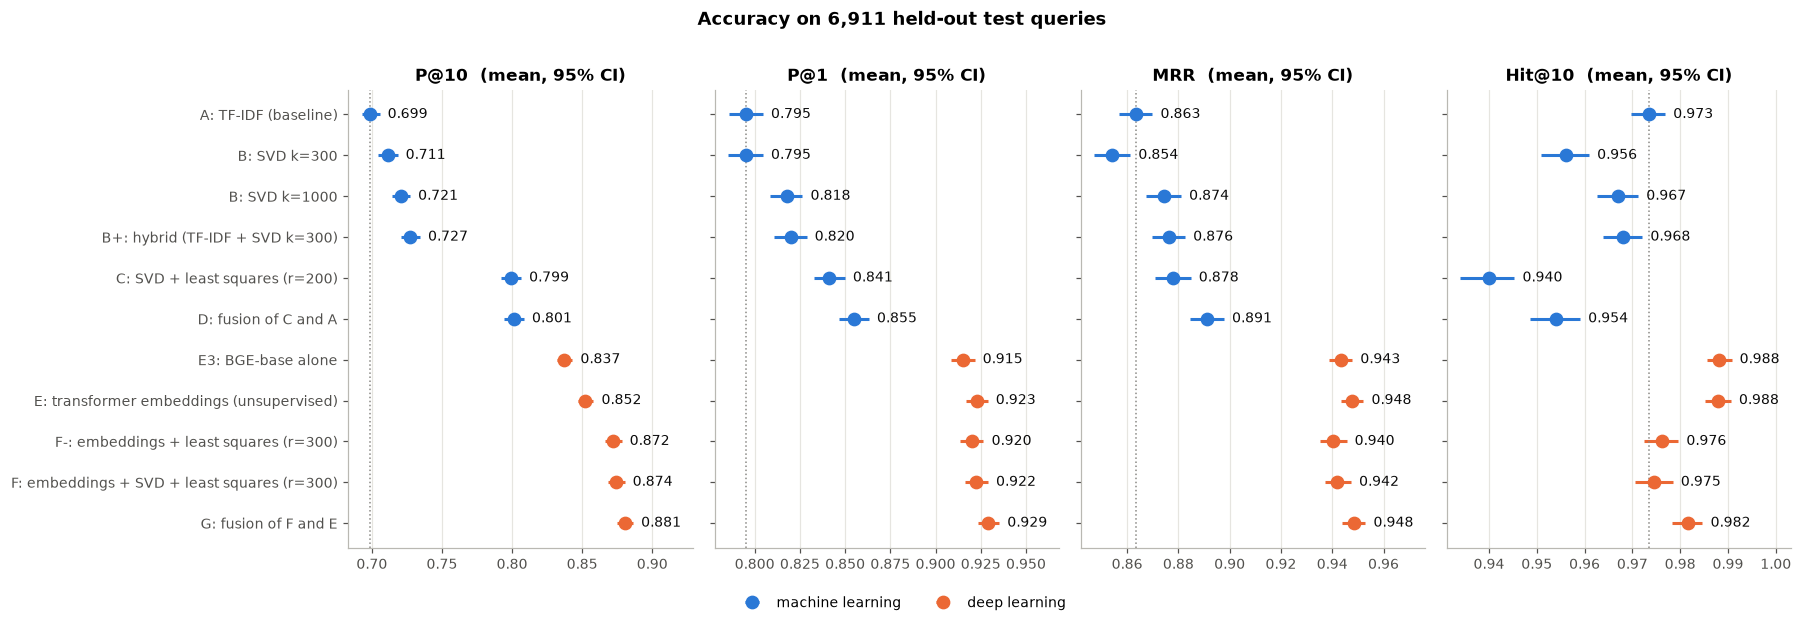

In [34]:
show = ["A: TF-IDF (baseline)", "B: SVD k=300", "B: SVD k=1000", name_Bp, name_C, name_D,
        "E3: BGE-base alone", name_E, name_Fm, name_F, name_G]
is_dl = np.array([s_ in DL_NAMES for s_ in show])
ypos = np.arange(len(show))[::-1]
fig, ax = plt.subplots(1, 4, figsize=(16.5, 5.2), sharey=True)
for a, mname in zip(ax, ["P@10", "P@1", "MRR", "Hit@10"]):
    mi = COL[mname]
    means = np.array([test_scores[s_][:, mi].mean() for s_ in show])
    cis = np.array([boot_ci(test_scores[s_][:, mi]) for s_ in show])
    for mask, colr, lab in [(~is_dl, BLUE, "machine learning"), (is_dl, ORANGE, "deep learning")]:
        a.errorbar(means[mask], ypos[mask], xerr=[means[mask] - cis[mask, 0], cis[mask, 1] - means[mask]], fmt="o",
                   color=colr, markersize=8, ecolor=colr, elinewidth=2, capsize=0, label=lab)
    for y_, v, hi_ in zip(ypos, means, cis[:, 1]):
        a.text(hi_ + (cis[:, 1].max() - cis[:, 0].min()) * 0.03, y_, "%.3f" % v, va="center", fontsize=9, color="#0b0b0b")
    a.axvline(means[0], color=GREY, lw=1, ls=":")
    span = cis[:, 1].max() - cis[:, 0].min()
    a.set_xlim(cis[:, 0].min() - 0.05 * span, cis[:, 1].max() + 0.22 * span); a.set_ylim(-0.6, len(show) - 0.4)
    a.set_title(mname + "  (mean, 95% CI)"); a.grid(axis="y", visible=False)
ax[0].set_yticks(ypos); ax[0].set_yticklabels(show)
handles, labels_ = ax[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Accuracy on 6,911 held-out test queries", y=1.01, fontsize=11.5, fontweight="bold")
plt.tight_layout(); plt.show()

**Reading the table and the chart.**

- The two families separate cleanly: **every deep-learning model is above every machine-learning model on
  Precision@10, P@1 and MRR**, and the confidence intervals do not overlap.
- Within each family the ordering has the same shape — unsupervised model, then the supervised least-squares head,
  then the fusion — which shows that the classical linear-algebra steps help on both kinds of features.
- **Hit@10 tells a slightly different story.** It is high for every model (0.92–0.99) and it is the one metric on
  which the supervised machine-learning models fall *below* the TF-IDF baseline. A model can raise the average
  number of relevant recommendations while failing completely on a few more queries, which is why several metrics
  are reported.

## 3.2 Head-to-head comparisons with significance tests

Averages can hide a lot, so each comparison below is **paired**: both models answer the same 6,911 queries and the
per-query differences are tested. Three like-for-like match-ups:

| Match-up | Machine learning | Deep learning | What it isolates |
|---|---|---|---|
| no labels at all | B+ (best unsupervised ML) | E | bag-of-words features vs pretrained neural features |
| same supervised head | C (head on SVD features) | F− (head on embeddings) | the features, with the learning algorithm held fixed |
| best of each family | D | G | the overall winner |

**What the code does** — runs `head_to_head` for the three match-ups (second model minus first), plus two reference
rows (baseline vs best model; the effect of adding SVD features to the embeddings), and prints the feature ablation
for the supervised head (SVD only / embeddings only / both).

In [35]:
matchups = {"no labels:  B+ (ML)  vs  E (DL)": (name_E, name_Bp),
            "same supervised head:  C (ML)  vs  F- (DL)": (name_Fm, name_C),
            "best of each family:  D (ML)  vs  G (DL + ML)": (name_G, name_D),
            "for reference:  A (baseline)  vs  G": (name_G, "A: TF-IDF (baseline)"),
            "adding SVD features to the embeddings:  F-  vs  F": (name_F, name_Fm)}
h2h = pd.DataFrame({k_: head_to_head(new_, base_) for k_, (new_, base_) in matchups.items()}).T
display(h2h.style.format({c_: "{:+.4f}" for c_ in ["Δ P@10", "Δ P@1", "Δ MRR", "Δ nDCG@10", "Δ Hit@10"]} |
                         {c_: "{:.4f}" for c_ in ["P@10 (first)", "P@10 (second)"]}))

print("Feature ablation for the supervised least-squares head (same algorithm, different input features)")
abl = pd.DataFrame({"SVD features only (model C, r=%d)" % R_SUP: summary(test_scores[name_C]),
                    "transformer embeddings only (model F-, r=%d)" % R_F: summary(test_scores[name_Fm]),
                    "embeddings + SVD features (model F, r=%d)" % R_F: summary(test_scores[name_F])}).T
abl[["P@1", "P@5", "P@10", "MRR", "nDCG@10", "Hit@10"]].round(4)

,P@10 (first),P@10 (second),Δ P@10,95% CI of Δ,paired t-test p,Δ P@1,Δ MRR,Δ nDCG@10,Δ Hit@10,queries better / equal / worse
no labels: B+ (ML) vs E (DL),0.7274,0.8523,+0.1250,"[+0.120, +0.130]",below 1e-300,+0.1029,+0.0716,+0.1213,+0.0198,3701 / 2558 / 652
same supervised head: C (ML) vs F- (DL),0.7992,0.8720,+0.0728,"[+0.068, +0.077]",1.0e-195,+0.0789,+0.0626,+0.0745,+0.0362,2299 / 4029 / 583
best of each family: D (ML) vs G (DL + ML),0.8014,0.8806,+0.0793,"[+0.075, +0.084]",2.7e-255,+0.0741,+0.0574,+0.0793,+0.0276,2478 / 3954 / 479
for reference: A (baseline) vs G,0.6990,0.8806,+0.1816,"[+0.176, +0.187]",below 1e-300,+0.1338,+0.0851,+0.1720,+0.0082,4551 / 1962 / 398
adding SVD features to the embeddings: F- vs F,0.8720,0.8741,+0.0021,"[+0.001, +0.003]",4.2e-03,+0.0023,+0.0016,+0.0023,-0.0016,665 / 5676 / 570


Feature ablation for the supervised least-squares head (same algorithm, different input features)


,P@1,P@5,P@10,MRR,nDCG@10,Hit@10
"SVD features only (model C, r=200)",0.8413,0.8160,0.7992,0.8778,0.8085,0.9400
"transformer embeddings only (model F-, r=300)",0.9201,0.8908,0.8720,0.9404,0.8830,0.9761
"embeddings + SVD features (model F, r=300)",0.9224,0.8943,0.8741,0.9420,0.8853,0.9745


**Reading the comparisons.**

1. **No labels (B+ vs E): +12.5 points of Precision@10 for deep learning** (0.727 → 0.852), with P@1 up by 10 points.
   Deep learning is better on 3,701 queries and worse on 652. This is the purest comparison of the two kinds of
   features: bag-of-words statistics of this corpus against knowledge transferred from pretraining.
2. **Same supervised head (C vs F−): +7.3 points** (0.799 → 0.872). The learning algorithm, the protocol and the
   compression are identical; only the input features differ. Labels narrow the gap between the families (from
   12.5 to 7.3 points) but do not close it.
3. **Best of each family (D vs G): +7.9 points** (0.801 → 0.881), +7.4 on P@1, +5.7 on MRR, +2.8 on Hit@10.
   Deep learning is better on 2,478 queries, equal on 3,954 and worse on 479.
4. **These three differences are statistically certain** — the 95% confidence intervals of the differences are far
   from zero and the paired t-test p-values are below $10^{-190}$.
5. **Feature ablation.** With the same least-squares head, SVD features give 0.799, transformer embeddings 0.872,
   and both together 0.874. Adding the classical SVD features to the embeddings raises Precision@10 by only
   0.002 (last row of the first table: statistically detectable, p ≈ 0.004, but practically negligible). Once deep
   features are available, the bag-of-words features contribute very little *accuracy*; their remaining value is
   cost and transparency (§3.5).

## 3.3 Where does each family win? — accuracy by research domain

**What the code does** — groups the test queries by the `domain` of the query paper (a column no model ever saw)
and reports Precision@10 of the baseline, the best machine-learning model and the best deep-learning model.

,test queries,A: TF-IDF,D: best ML,"E: DL, no labels",G: best DL,gain of G over D
domain of the query paper,,,,,,
Machine Learning,1351,0.613,0.706,0.784,0.827,0.121
Software Engineering,1315,0.669,0.762,0.818,0.836,0.075
Artificial Intelligence,1261,0.709,0.836,0.887,0.914,0.078
Computer Vision,987,0.632,0.728,0.804,0.844,0.117
Natural Language Processing,1008,0.804,0.884,0.901,0.923,0.039
Cybersecurity,989,0.803,0.930,0.946,0.964,0.034


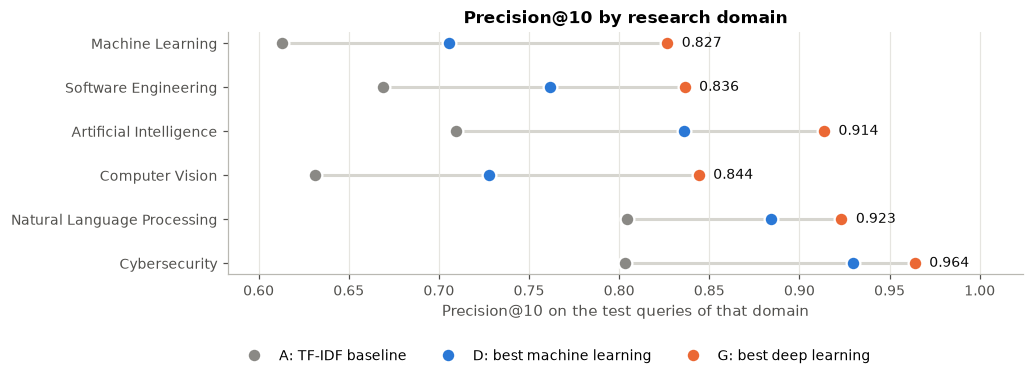

In [36]:
dom_test = df["domain"].to_numpy()[TEST]
domains = list(df["domain"].value_counts().index)
by_dom = pd.DataFrame({"test queries": [int((dom_test == d_).sum()) for d_ in domains],
                       "A: TF-IDF": [test_scores["A: TF-IDF (baseline)"][dom_test == d_, COL["P@10"]].mean() for d_ in domains],
                       "D: best ML": [test_scores[name_D][dom_test == d_, COL["P@10"]].mean() for d_ in domains],
                       "E: DL, no labels": [test_scores[name_E][dom_test == d_, COL["P@10"]].mean() for d_ in domains],
                       "G: best DL": [test_scores[name_G][dom_test == d_, COL["P@10"]].mean() for d_ in domains]},
                      index=pd.Index(domains, name="domain of the query paper"))
by_dom["gain of G over D"] = by_dom["G: best DL"] - by_dom["D: best ML"]
display(by_dom.round(3))

fig, ax = plt.subplots(figsize=(9.5, 3.9))
yd = np.arange(len(domains))[::-1]
for col_, colr, lab in [("A: TF-IDF", GREY, "A: TF-IDF baseline"), ("D: best ML", BLUE, "D: best machine learning"),
                        ("G: best DL", ORANGE, "G: best deep learning")]:
    ax.plot(by_dom[col_], yd, "o", color=colr, markersize=9, markeredgecolor="white", markeredgewidth=1.5, label=lab)
for y_, lo_, hi_ in zip(yd, by_dom["A: TF-IDF"], by_dom["G: best DL"]):
    ax.plot([lo_, hi_], [y_, y_], color="#d6d5cf", lw=2, zorder=0)
    ax.text(hi_ + 0.008, y_, "%.3f" % hi_, va="center", fontsize=9, color="#0b0b0b")
ax.set_yticks(yd); ax.set_yticklabels(domains); ax.set_xlabel("Precision@10 on the test queries of that domain")
ax.set_xlim(by_dom["A: TF-IDF"].min() - 0.03, by_dom["G: best DL"].max() + 0.06); ax.grid(axis="y", visible=False)
ax.set_title("Precision@10 by research domain"); ax.legend(loc="lower left", ncol=3, bbox_to_anchor=(0, -0.42))
plt.tight_layout(); plt.show()

**Reading the breakdown.**

- **Deep learning is the most accurate in every one of the six domains**, and the ordering baseline < best ML <
  best DL holds everywhere.
- **The gain is largest where bag-of-words is weakest.** In *Machine Learning* (+12.1 points over the best
  machine-learning model) and *Computer Vision* (+11.7) the vocabulary is generic — "model", "learning", "data",
  "image" occur across many topics — so word overlap is a poor guide and understanding of meaning matters most.
- **The gain is smallest where the vocabulary is distinctive.** In *Cybersecurity* (+3.4) and *Natural Language
  Processing* (+3.9) specialised terms identify the topic almost by themselves, and the machine-learning model is
  already at 0.93 and 0.88.
- Difficulty differs by domain for both families: Cybersecurity is the easiest (0.964 for G), Machine Learning and
  Software Engineering the hardest (0.827 and 0.836), because their topics overlap most.

## 3.4 Query-level behaviour: who wins on individual queries, and do the two families agree?

**What the code does**

- Plots the distribution of the per-query difference in Precision@10 between the best deep-learning model (G) and
  the best machine-learning model (D).
- `top10` extracts the actual recommendation lists; the average overlap between the lists of two models shows how
  differently they behave.
- Computes an *oracle* that picks, for each query, whichever of D and G is better — an upper bound on what
  combining the two families could add.

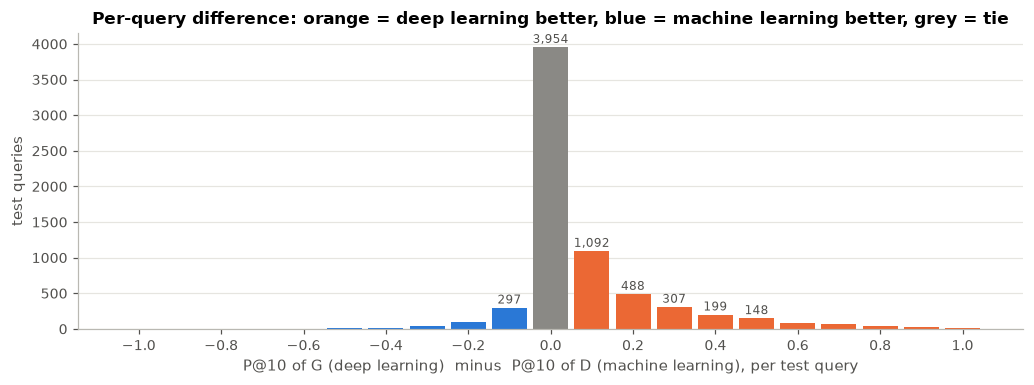

Deep learning better on 2478 queries (35.9%), equal on 3954 (57.2%), machine learning better on 479 (6.9%)



Average number of papers (out of 10) that two models recommend in common, on 1,500 test queries:
   A: TF-IDF                    and  D: fusion of C and A         : 4.0
   A: TF-IDF                    and  G: fusion of F and E         : 3.1
   D: fusion of C and A         and  G: fusion of F and E         : 3.8
   E: transformer embeddings    and  G: fusion of F and E         : 6.1

Oracle that picks the better of D and G per query: P@10 = 0.8924   (G alone: 0.8806, D alone: 0.8014)


In [37]:
d_pq = test_scores[name_G][:, COL["P@10"]] - test_scores[name_D][:, COL["P@10"]]
vals = np.round(np.arange(-1.0, 1.0001, 0.1), 1)
counts = np.array([(np.round(d_pq, 1) == v).sum() for v in vals])
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.bar(vals, counts, width=0.085, color=[ORANGE if v > 0 else (BLUE if v < 0 else GREY) for v in vals])
for v, c_ in zip(vals, counts):
    if c_ > 0.03 * counts.max():
        ax.text(v, c_ + counts.max() * 0.015, "{:,}".format(c_), ha="center", fontsize=8, color="#52514e")
ax.set_xlabel("P@10 of G (deep learning)  minus  P@10 of D (machine learning), per test query")
ax.set_ylabel("test queries"); ax.set_xticks(np.round(np.arange(-1, 1.01, 0.2), 1)); ax.grid(axis="x", visible=False)
ax.set_title("Per-query difference: orange = deep learning better, blue = machine learning better, grey = tie")
plt.tight_layout(); plt.show()
print("Deep learning better on %d queries (%.1f%%), equal on %d (%.1f%%), machine learning better on %d (%.1f%%)"
      % ((d_pq > 0).sum(), 100 * (d_pq > 0).mean(), (d_pq == 0).sum(), 100 * (d_pq == 0).mean(),
         (d_pq < 0).sum(), 100 * (d_pq < 0).mean()))

def top10(sim_fn, queries, chunk=500):
    '''The 10 recommended paper indices for each query (same masking and ordering as evaluate).'''
    out = []
    for s0 in range(0, len(queries), chunk):
        q = queries[s0:s0 + chunk]
        S_ = np.asarray(sim_fn(q), dtype=np.float32); S_[np.arange(len(q)), q] = -np.inf
        top = np.argpartition(-S_, 10, axis=1)[:, :10]
        out.append(np.take_along_axis(top, np.argsort(-np.take_along_axis(S_, top, axis=1), axis=1), axis=1))
    return np.vstack(out)

q_sub = TEST[:1500]
lists = {nm: top10(methods[nm][0], q_sub) for nm in ["A: TF-IDF (baseline)", name_D, name_E, name_G]}
overlap = lambda a_, b_: np.mean([len(set(x_) & set(y_)) for x_, y_ in zip(lists[a_], lists[b_])])
print("\nAverage number of papers (out of 10) that two models recommend in common, on 1,500 test queries:")
for a_, b_ in [("A: TF-IDF (baseline)", name_D), ("A: TF-IDF (baseline)", name_G), (name_D, name_G), (name_E, name_G)]:
    print("   %-28s and  %-28s : %.1f" % (a_.split(" (")[0], b_.split(" (")[0], overlap(a_, b_)))

oracle = np.maximum(test_scores[name_G][:, COL["P@10"]], test_scores[name_D][:, COL["P@10"]]).mean()
print("\nOracle that picks the better of D and G per query: P@10 = %.4f   (G alone: %.4f, D alone: %.4f)"
      % (oracle, test_scores[name_G][:, COL["P@10"]].mean(), test_scores[name_D][:, COL["P@10"]].mean()))

**Reading the query-level results.**

- **Most queries are a tie or a deep-learning win.** On 57% of the test queries the two best models have exactly
  the same Precision@10; deep learning is better on 36% and machine learning on 7%. When deep learning wins it
  often wins by several papers out of ten; when machine learning wins it is usually by one.
- **The two families recommend different papers.** The best machine-learning and deep-learning models share on
  average only 3.8 of their 10 recommendations, even though both lists are 80–88% relevant. With roughly 800
  relevant papers per query there are many correct answers, and each representation reaches a different part of them.
- **But there is little left to gain from combining them.** An oracle that knew, for each query, which of the two
  models is better would reach Precision@10 = 0.892 — only 1.2 points above the deep-learning model alone. This
  agrees with the ablation of §3.2: the deep features already cover almost everything the classical features offer.

## 3.5 Efficiency: speed, size and cost

Accuracy is one side of the comparison; the other is what each model costs.

- **dimensions** of the vectors that are compared;
- **storage** of the document matrix (sparse for TF-IDF, dense `float32` otherwise);
- **query time** — time to score one query paper against all 9,956 papers, best of three passes over 300 queries;
- **one-off costs** — building the representation.

**What the code does** — `time_per_query` times each scoring function; the table combines timing, dimensions,
storage and test nDCG@10; the chart shows the three cost measures.

In [38]:
def time_per_query(score_one, queries, repeats=3):
    best = np.inf
    for _ in range(repeats):                                 # best of 3 passes -> less timing noise
        t0 = time.perf_counter()
        for qi in queries:
            score_one(qi)
        best = min(best, time.perf_counter() - t0)
    return 1000 * best / len(queries)

bench_q = TEST[:300]
score_fns = {"A: TF-IDF (baseline)": lambda qi: (A @ A[qi].T).toarray().ravel()}
for k in K_VALUES:
    score_fns["B: SVD k=%d" % k] = (lambda V_: (lambda qi: V_ @ V_[qi]))(Zn[k])
score_fns[name_C] = lambda qi: R_all @ R_all[qi]
score_fns["D: fusion of C and A"] = lambda qi: (1 - BETA) * (R_all @ R_all[qi]) + BETA * (A @ A[qi].T).toarray().ravel()
score_fns["E: transformer embeddings (unsupervised)"] = lambda qi: E_cat @ E_cat[qi]
score_fns[name_F] = lambda qi: R_F_all @ R_F_all[qi]
score_fns["G: fusion of F and E"] = lambda qi: (1 - W_G) * (R_F_all @ R_F_all[qi]) + W_G * (E_cat @ E_cat[qi])

sparse_mb = (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6
eff = []
for name, fn in score_fns.items():
    dims = methods[name][1]
    if name.startswith("A:"):   store = sparse_mb
    elif name.startswith("D:"): store = sparse_mb + R_all.nbytes / 1e6
    elif name.startswith("C:"): store = R_all.nbytes / 1e6
    elif name.startswith("E:"): store = E_cat.nbytes / 1e6
    elif name.startswith("F:"): store = R_F_all.nbytes / 1e6
    elif name.startswith("G:"): store = (R_F_all.nbytes + E_cat.nbytes) / 1e6
    else:                       store = Zn[dims].nbytes / 1e6
    eff.append(dict(method=name, dims=dims, storage_MB=store, query_ms=time_per_query(fn, bench_q),
                    **{"nDCG@10": test_scores[name][:, 4].mean()}))
eff = pd.DataFrame(eff).set_index("method")
eff["speed-up vs A"] = eff.loc["A: TF-IDF (baseline)", "query_ms"] / eff["query_ms"]
print("One-off costs:  TF-IDF build %.1fs | rank-%d SVD %.1fs | least-squares map + second SVD: C %.1fs, F %.1fs"
      % (build_time_tfidf, K_MAX, svd_fit_time, sup_fit_time, supF_fit_time))
print("                Transformer embeddings of the corpus: about 4.5 minutes once on a laptop GPU (cached in data/).")
eff.style.format({"dims": "{:,}", "storage_MB": "{:.1f}", "query_ms": "{:.3f}", "nDCG@10": "{:.4f}", "speed-up vs A": "{:.1f}×"})

One-off costs:  TF-IDF build 0.6s | rank-1000 SVD 8.8s | least-squares map + second SVD: C 0.2s, F 1.0s
                Transformer embeddings of the corpus: about 4.5 minutes once on a laptop GPU (cached in data/).


,dims,storage_MB,query_ms,nDCG@10,speed-up vs A
method,,,,,
A: TF-IDF (baseline),"31,291",11.5,1.859,0.7198,1.0×
B: SVD k=50,50,2.0,0.020,0.6801,91.3×
B: SVD k=100,100,4.0,0.023,0.7010,82.3×
B: SVD k=200,200,8.0,0.024,0.7196,76.4×
B: SVD k=300,300,11.9,0.029,0.7289,63.7×
B: SVD k=500,500,19.9,0.059,0.7378,31.6×
B: SVD k=1000,"1,000",39.8,0.160,0.7412,11.6×
C: SVD + least squares (r=200),200,8.0,0.024,0.8085,79.1×
D: fusion of C and A,"31,491",19.5,1.927,0.8126,1.0×


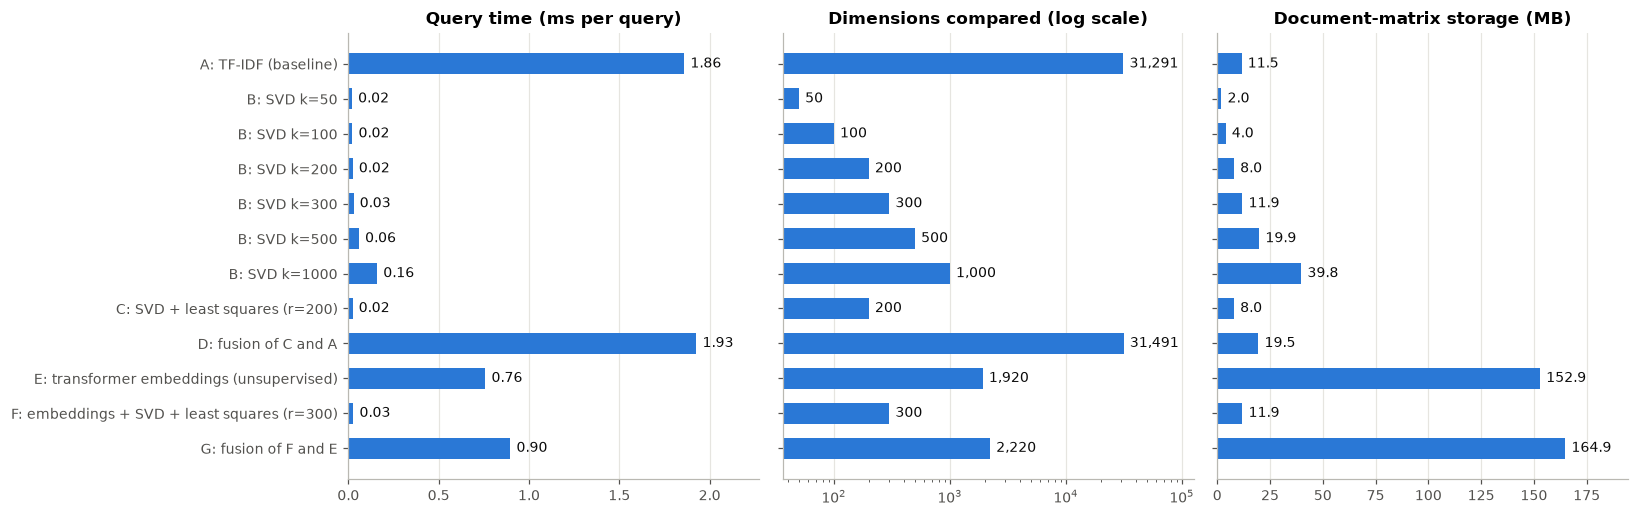

In [39]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
names = list(eff.index); ypos = np.arange(len(names))[::-1]
for a, col, title, fmt in [(ax[0], "query_ms", "Query time (ms per query)", "%.2f"),
                           (ax[1], "dims", "Dimensions compared (log scale)", "%d"),
                           (ax[2], "storage_MB", "Document-matrix storage (MB)", "%.1f")]:
    a.barh(ypos, eff[col], height=0.6, color=BLUE)
    if col == "dims": a.set_xscale("log")
    for y_, v in zip(ypos, eff[col]):
        a.annotate(("{:,}".format(int(v)) if col == "dims" else fmt % v), (v, y_), textcoords="offset points",
                   xytext=(4, 0), va="center", fontsize=9, color="#0b0b0b")
    a.set_title(title); a.grid(axis="y", visible=False)
    a.set_xlim(right=eff[col].max() * (4 if col == "dims" else 1.18))
ax[0].set_yticks(ypos); ax[0].set_yticklabels(names)
plt.tight_layout(); plt.show()

**Reading the efficiency results.** (Timings depend on the machine and vary between runs; dimensions and storage are exact.)

| | Machine learning | Deep learning |
|---|---|---|
| Building the representation | TF-IDF < 1 s, SVD ≈ 9–15 s, on a CPU | ≈ 4.5 minutes on a laptop GPU for three encoders (once; cached) |
| External requirements | none | PyTorch + ≈ 1 GB of pretrained weights |
| Vector for a new query | well under a millisecond | tens of milliseconds (three forward passes) |
| Index size, best compact model | C: 200 dims, 8 MB | F: 300 dims, 12 MB |
| Index size, raw features | A: sparse, 11.5 MB | E: 1,920 dims, 153 MB |
| Scoring one query against the corpus | A: ≈ 2 ms; C: ≈ 0.03 ms | E: ≈ 1 ms; F: ≈ 0.03 ms |

- **Raw deep embeddings are accurate but heavy**: a 13× larger index than TF-IDF.
- **Dimensionality reduction removes that penalty.** The least-squares + SVD head compresses the embeddings to 300
  dimensions — the same size and speed as the compact machine-learning model — while *raising* accuracy
  (nDCG@10 0.885 for F against 0.869 for the raw embeddings E). The linear algebra of Part 1 is what makes the deep
  model practical.
- **Machine learning remains the cheapest to build and deploy**: no GPU, no downloads, seconds instead of minutes.

## 3.6 How each family organises the corpus

A 2-D projection of each representation, one panel per research domain (that domain in colour, all other papers in
grey). Top row: the machine-learning latent space (singular directions 2 and 3 of the TF-IDF matrix). Bottom row:
the deep-learning embedding space (first two principal components of the combined embeddings). The `domain` label
was never given to any model.

**What the code does** — projects a random sample of 4,000 papers and draws the 2 × 6 grid.

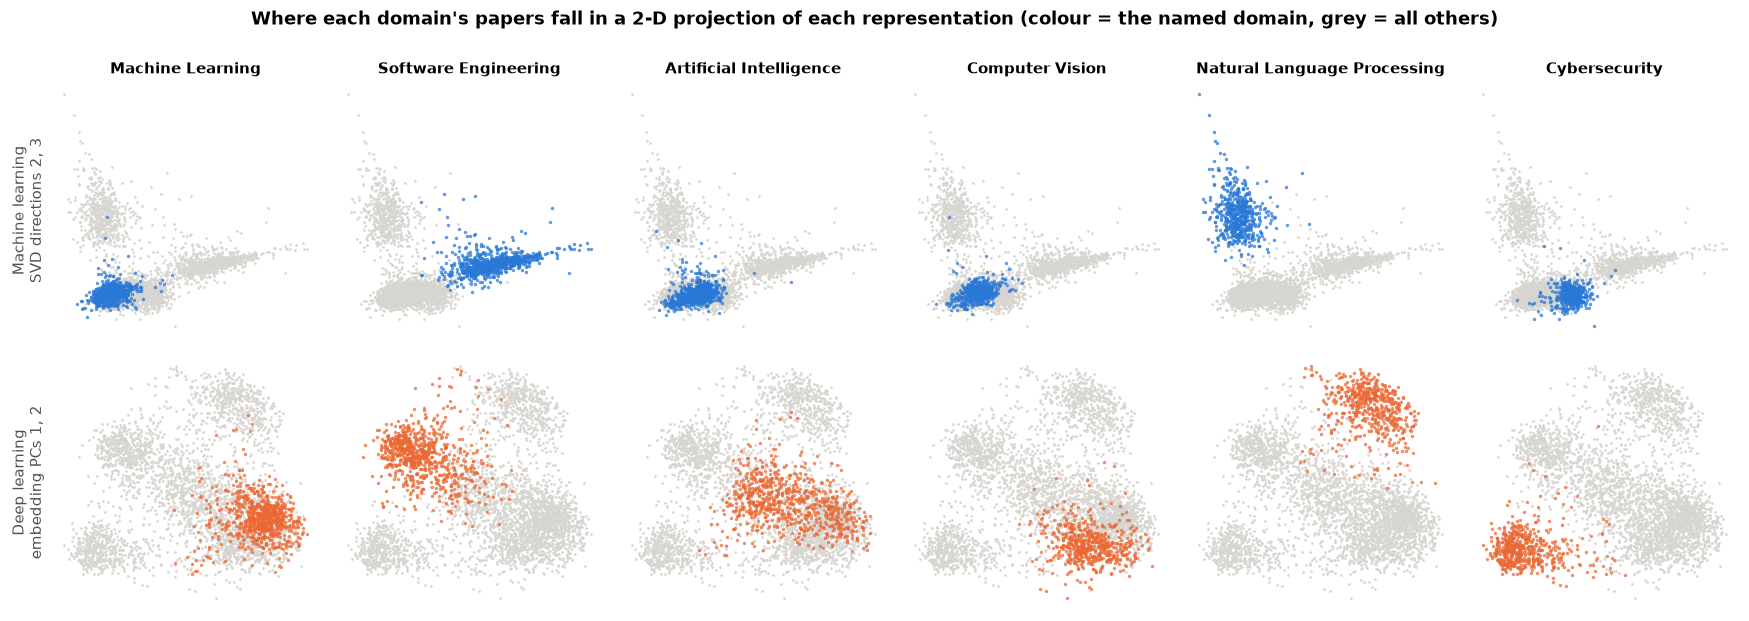

In [40]:
samp = np.random.default_rng(SEED).choice(N, 4000, replace=False)
dom_s = df["domain"].to_numpy()[samp]
Ec = E_cat - E_cat.mean(axis=0)                                  # PCA of the embeddings = SVD of the centred matrix
pc = TruncatedSVD(n_components=2, random_state=SEED).fit_transform(Ec)
proj = [("Machine learning\nSVD directions 2, 3", Z[samp, 1:3], BLUE), ("Deep learning\nembedding PCs 1, 2", pc[samp], ORANGE)]

fig, axes = plt.subplots(2, len(domains), figsize=(16, 5.6))
for r_, (pname, P2, colr) in enumerate(proj):
    for c_, dom in enumerate(domains):
        a = axes[r_, c_]; is_dom = dom_s == dom
        a.scatter(P2[~is_dom, 0], P2[~is_dom, 1], s=3, color="#d6d5cf", linewidths=0, rasterized=True)
        a.scatter(P2[is_dom, 0], P2[is_dom, 1], s=5, color=colr, alpha=0.75, linewidths=0, rasterized=True)
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
        for sp_ in a.spines.values(): sp_.set_visible(False)
        if r_ == 0: a.set_title(dom, fontsize=10)
        if c_ == 0: a.set_ylabel(pname, fontsize=9.5)
fig.suptitle("Where each domain's papers fall in a 2-D projection of each representation (colour = the named domain, grey = all others)",
             y=1.0, fontsize=11.5, fontweight="bold")
plt.tight_layout(); plt.show()

In both rows each domain occupies its own region, although no model was given the domain. The machine-learning
projection separates Natural Language Processing, Software Engineering and Cybersecurity but piles Machine
Learning, Artificial Intelligence and Computer Vision on top of each other; in the deep-learning projection the six
domains spread into more distinct groups (Machine Learning, Artificial Intelligence and Computer Vision still
neighbour each other, as their subjects do). A 2-D picture shows only a small part of either space, but it agrees
with §3.3: the deep representation separates precisely the domains that the bag-of-words representation confuses.

## 3.7 Example outputs side by side

Numbers aside, what do the two families actually recommend? The deployment models (trained on all labelled papers;
used only for this demonstration, never for the accuracy figures) answer the same paper query and the same
free-text queries.

**What the code does**

- Verifies the SVD closed form of ridge regression, then defines the query pipeline: `embed_query` (TF-IDF →
  fold-in to SVD space), `predict_topics`, `search` (models A–D), `embed_query_deep` / `search_deep` (model G: the
  query is encoded by the three transformers, joined with its SVD vector, projected with `L_F_all`, and fused with
  the raw embedding score), and `recommend` for papers of the corpus.
- Shows the recommendations of the best machine-learning model (D) and the best deep-learning model (G) for one
  paper and three free-text queries. Free-text search with G needs the encoders; without PyTorch only D is shown.

In [41]:
# ---- numerical check of the SVD closed form of ridge regression (all rows, so Z^T Z = Sigma^2) -------
G = Z.T @ Z
W_normal = sla.solve(G + LAMBDA * np.eye(K_MAX), Z.T @ Y, assume_a="pos")          # normal equations
W_svd = (sigma / (sigma ** 2 + LAMBDA))[:, None] * ((Z / sigma).T @ Y)             # (S^2 + lam I)^-1 S U^T Y
print("Z^T Z is diagonal (= Sigma^2):  max off-diagonal = %.1e,  max |diag - sigma^2| = %.1e"
      % (np.abs(G - np.diag(np.diag(G))).max(), np.abs(np.diag(G) - sigma ** 2).max()))
print("normal equations vs SVD closed form:  max |difference| = %.1e" % np.abs(W_normal - W_svd).max())

# W for topic prediction is trained on labelled papers only (unlabelled papers carry no information)
Xl = Z[has_topic]
W_all = sla.solve(Xl.T @ Xl + LAMBDA * np.eye(K_MAX), Xl.T @ Y[has_topic], assume_a="pos")

def embed_query(query):
    '''free text -> (TF-IDF row vector q, latent vector z_q = q V_k)'''
    q = vectorizer.transform([preprocess(query)])            # 1 x n sparse, unit length
    return q, svd.transform(q)                               # fold-in: z_q = q V_k   (1 x 1000)

def predict_topics(query, top=3):
    _, zq = embed_query(query)
    scores = (zq @ W_all).ravel()
    best = np.argsort(-scores)[:top]
    return [(topic_names[i], round(float(scores[i]), 3)) for i in best]

def search(query, method="fusion", k=5):
    '''Recommend papers for a free-text query.  method in {"tfidf", "svd", "supervised", "fusion"}.'''
    q, zq = embed_query(query)
    s_tfidf = (A @ q.T).toarray().ravel()                                    # Approach A
    if method == "tfidf":
        sims = s_tfidf
    elif method == "svd":
        sims = Zn[K_HYB] @ normalize(zq[:, :K_HYB]).ravel().astype(np.float32)   # Approach B
    else:
        s_sup = R_all @ normalize(zq.astype(np.float32) @ L_all).ravel()     # Approach C
        sims = s_sup if method == "supervised" else (1 - BETA) * s_sup + BETA * s_tfidf   # Approach D
    return result_table(sims, top_k(sims, k), cols=("title", "authors", "year", "domain"))

def embed_query_deep(query):
    '''free text -> (e_q: 1,920-d unit embedding vector,  x_q: r-dimensional learned vector of Approach F)'''
    _, zq = embed_query(query)
    parts = [encode(k_, [query]) for k_ in EMB_MODELS]                        # one forward pass per encoder
    e_q = np.hstack(parts).ravel() / np.sqrt(len(EMB_MODELS))
    x_q = np.hstack([S_F * p for p in parts] + [zq]).astype(np.float32)       # same feature layout as X_F
    return e_q, normalize(x_q @ L_F_all).ravel()

def search_deep(query, k=5):
    '''Approach G for a free-text query (needs torch + sentence-transformers to encode the query).'''
    e_q, x_q = embed_query_deep(query)
    sims = (1 - W_G) * (R_F_all @ x_q) + W_G * (E_cat @ e_q)
    return result_table(sims, top_k(sims, k), cols=("title", "authors", "year", "domain"))

def recommend(idx, method="deep", k=5):
    '''Recommend papers similar to corpus paper `idx` with the final models (no encoder needed: vectors are stored).'''
    s_tfidf = (A @ A[idx].T).toarray().ravel()
    s_sup = R_all @ R_all[idx]
    sims = {"tfidf": s_tfidf, "svd": Zn[K_HYB] @ Zn[K_HYB][idx], "supervised": s_sup,
            "fusion": (1 - BETA) * s_sup + BETA * s_tfidf,
            "deep": (1 - W_G) * (R_F_all @ R_F_all[idx]) + W_G * (E_cat @ E_cat[idx])}[method]
    sims = np.array(sims, dtype=np.float32); sims[idx] = -np.inf
    return result_table(sims, top_k(sims, k))

Z^T Z is diagonal (= Sigma^2):  max off-diagonal = 5.9e-13,  max |diag - sigma^2| = 1.3e-12
normal equations vs SVD closed form:  max |difference| = 1.4e-14


In [42]:
try:                                   # free-text queries for model G need the encoders (optional packages)
    for k_ in EMB_MODELS:
        get_encoder(k_)
    DEEP_OK = True
except Exception as e:
    DEEP_OK = False
    print("Transformer encoders unavailable (%s) - free-text examples show the machine-learning model only." % type(e).__name__)

print("QUERY PAPER:", df["title"].iloc[seed])
print("\n  Machine learning (model D)"); display(recommend(seed, "fusion", 5))
print("  Deep learning (model G)");      display(recommend(seed, "deep", 5))

for qtext in ["Graph neural networks for financial fraud detection",
              "transformer models for machine translation",
              "adversarial attacks on image classifiers"]:
    print("=" * 110)
    print("QUERY:", qtext)
    print("Predicted topics:", "; ".join("%s (%.2f)" % t for t in predict_topics(qtext)))
    print("\n  Machine learning (model D)"); display(search(qtext, method="fusion", k=5))
    if DEEP_OK:
        print("  Deep learning (model G)"); display(search_deep(qtext, k=5))

QUERY PAPER: Machine learning and deep learning

  Machine learning (model D)


,similarity,title,domain,year
0,0.528,REVIEW OF MACHINE LEARNING,Machine Learning,2025.0
1,0.507,A SURVEY ON MACHINE LEARNING,Machine Learning,2021.0
2,0.506,A tour of machine learning,Machine Learning,2014.0
3,0.491,Machine Learning In Finance,Machine Learning,2023.0
4,0.489,Defining Artificial Intelligence,Artificial Intelligence,2019.0


  Deep learning (model G)


,similarity,title,domain,year
0,0.799,Advances in Machine Learning and Deep Neural Networks,Machine Learning,2021.0
1,0.778,Artificial intelligence. Machine learning,Machine Learning,2019.0
2,0.770,Artificial intelligence and machine learning,Machine Learning,2022.0
3,0.769,"Artificial intelligence: a survey on evolution, models, applications and future trends",Artificial Intelligence,2019.0
4,0.768,Artificial intelligence within the interplay between natural and artificial computatio...,Artificial Intelligence,2020.0


QUERY: Graph neural networks for financial fraud detection
Predicted topics: digital transformation in financial services (0.23); cybercrime and law enforcement studies (0.23); advanced graph neural networks (0.19)

  Machine learning (model D)


,similarity,title,authors,year,domain
0,0.354,Machine learning: A revolution in risk management and compliance?,Bart. Van Liebergen,2017.0,Machine Learning
1,0.347,Machine Learning in Financial Crisis Prediction: A Survey,Wei-Yang Lin; Ya‐Han Hu; Chih‐Fong Tsai,2011.0,Machine Learning
2,0.330,Artificial intelligence and fintech: An overview of opportunities and risks for bankin...,Arvind Ashta; Heinz Herrmann,2021.0,Artificial Intelligence
3,0.328,The impact of machine learning on UK financial services,Bonnie Buchanan; Danika Wright,2021.0,Machine Learning
4,0.300,Cybersecurity in the Financial Sector,Kalyani Priyadarshani; A. Rengarajan,2024.0,Cybersecurity


... (6 outputs left out)

QUERY: adversarial attacks on image classifiers
Predicted topics: adversarial robustness in machine learning (1.17); security and verification in computing (0.49); digital media forensic detection (0.49)

  Machine learning (model D)


,similarity,title,authors,year,domain
0,0.686,Adversarial attacks on medical machine learning,Samuel G. Finlayson; John D. Bowers; Joichi Ito; Jonathan L. Zittrain; Andrew L. Beam;...,2019.0,Machine Learning
1,0.665,Adversarial Attacks and Defenses in Deep Learning: From a Perspective of Cybersecurity,Shuai Zhou; Chi Liu; Dayong Ye; Tianqing Zhu; Wanlei Zhou; Philip S. Yu,2022.0,Cybersecurity
2,0.626,Review of Artificial Intelligence Adversarial Attack and Defense Technologies,Shilin Qiu; Qihe Liu; Shijie Zhou; Chunjiang Wu,2019.0,Artificial Intelligence
3,0.616,Threat of Adversarial Attacks on Deep Learning in Computer Vision: A Survey,Naveed Akhtar; Ajmal Saeed Mian,2018.0,Computer Vision
4,0.612,Physical Adversarial Attack Meets Computer Vision: A Decade Survey,Hui Wei; Hao Tang; Xuemei Jia; Zhixiang Wang; Hanxun Yu; Zhubo Li; Shin’ichi Satoh; Lu...,2024.0,Computer Vision


  Deep learning (model G)


,similarity,title,authors,year,domain
0,0.794,Threat of Adversarial Attacks on Deep Learning in Computer Vision: A Survey,Naveed Akhtar; Ajmal Saeed Mian,2018.0,Computer Vision
1,0.783,Adversarial Examples that Fool both Human and Computer Vision,Gamaleldin F. Elsayed; Shreya Shankar; Brian Cheung; Nicolas Papernot; Alexey Kurakin;...,2018.0,Computer Vision
2,0.781,Adversarial attacks on medical machine learning,Samuel G. Finlayson; John D. Bowers; Joichi Ito; Jonathan L. Zittrain; Andrew L. Beam;...,2019.0,Machine Learning
3,0.776,Adversarial machine learning for cybersecurity and computer vision: Current developmen...,Bowei Xi,2020.0,Computer Vision
4,0.772,Physical Adversarial Attack Meets Computer Vision: A Decade Survey,Hui Wei; Hao Tang; Xuemei Jia; Zhixiang Wang; Hanxun Yu; Zhubo Li; Shin’ichi Satoh; Lu...,2024.0,Computer Vision


**Reading the examples.**

- *Paper query "Machine learning and deep learning".* Both models return sensible overviews. The machine-learning
  list is driven by the shared words "machine learning"; the deep-learning list also brings in papers on neural
  networks and AI surveys that describe the same subject in other words.
- *"transformer models for machine translation".* The machine-learning model matches the words "machine translation"
  and returns general translation papers; the deep-learning model puts papers that are actually about
  **transformers** in NLP first — it understands that the query is about a model architecture.
- *"Graph neural networks for financial fraud detection".* Neither model returns a paper on graph neural networks
  for fraud — the corpus does not appear to contain a close match. The machine-learning model falls back on
  finance-and-ML papers; the deep-learning model finds the closest *meaning* (money-laundering detection, credit
  risk, fraud detection). This is the "sparse neighbourhood" situation analysed in Part 2.
- *"adversarial attacks on image classifiers".* A well-covered subject with distinctive vocabulary: both models are
  excellent and largely agree.

### Live widget

Inside Jupyter the cell below gives a text box and a model selector (in a static export only the initial result is
visible). The Streamlit app `app.py` offers the same models in a browser: `streamlit run app.py`.

In [43]:
try:
    import ipywidgets as W_
    from IPython.display import display as _show, clear_output
    box = W_.Text(value="Graph neural networks for fraud detection", description="Query:", layout=W_.Layout(width="60%"))
    options = [("D: fusion of C and A", "fusion"), ("C: SVD + least squares", "supervised"), ("B: SVD", "svd"), ("A: TF-IDF", "tfidf")]
    if DEEP_OK:
        options.insert(0, ("G: deep fusion (best)", "deep"))
    model = W_.Dropdown(options=options, value=options[0][1], description="Model:")
    out = W_.Output()
    def _run(_=None):
        with out:
            clear_output()
            print("Predicted topics:", "; ".join("%s (%.2f)" % t for t in predict_topics(box.value)))
            _show(search_deep(box.value, k=8) if model.value == "deep" else search(box.value, method=model.value, k=8))
    box.on_submit(_run); model.observe(_run, "value")
    _run()
    _show(W_.VBox([W_.HBox([box, model]), out]))
except Exception as e:
    print("Widget unavailable (%s) - call search('your query') directly." % type(e).__name__)

---
# Conclusions

## Summary of the comparison

| Criterion | Machine learning (Part 1) | Deep learning (Part 2) | Better |
|---|---|---|---|
| Precision@10, no labels | 0.727 (B+) | 0.852 (E) | deep learning, +12.5 points |
| Precision@10, same supervised head | 0.799 (C) | 0.872 (F−) | deep learning, +7.3 points |
| Precision@10, best model | 0.801 (D) | 0.881 (G) | deep learning, +7.9 points |
| P@1 / MRR / Hit@10, best model | 0.855 / 0.891 / 0.954 | 0.929 / 0.948 / 0.982 | deep learning |
| Wins by research domain | 0 of 6 | 6 of 6 | deep learning |
| Per-query result (D vs G) | better on 7% | better on 36% (tie on 57%) | deep learning |
| Time to build | seconds, CPU | minutes, GPU recommended | machine learning |
| External dependencies | none | PyTorch + ≈1 GB of pretrained weights | machine learning |
| Cost of a new query vector | < 1 ms | tens of ms | machine learning |
| Transparency | every step is closed-form and inspectable | 23–110 M-parameter black boxes | machine learning |
| Compact index (≤ 300 dims) | C: P@10 0.799 | F: P@10 0.874 | deep features + classical head |

## Answers to the three questions

1. **Machine learning.** TF-IDF with cosine similarity scores Precision@10 = 0.699. Truncated SVD matches it with
   156× fewer dimensions and improves it slightly at higher rank (0.721); a ridge least-squares map on the SVD
   space, compressed by a second SVD, reaches **0.799 in 200 dimensions**, and **0.801** when fused with TF-IDF.
   It is fast, transparent and self-contained, and its accuracy saturates around 0.80.
2. **Deep learning.** Pretrained transformer encoders reach **0.852 without any labels** and **0.881** with the
   supervised head and fusion (P@1 0.929, MRR 0.948, Hit@10 0.982). They are more accurate on every metric, in every
   domain and under every protocol, at the price of heavy external models and compute.
3. **Comparison.** Deep learning is the more *accurate* family by 7–13 points of Precision@10, with differences that
   are statistically certain. Machine learning is the more *economical and explainable* family. They are not
   rivals in the final system: the best practical model (**F**) uses deep-learning features, the machine-learning
   head (ridge least squares) and the linear-algebra compression (SVD) together — 300 dimensions, about 60× faster
   to query than TF-IDF, Precision@10 = 0.874.

## Which one to use

- **No GPU, no external downloads, or a need to explain every step:** model C or D (machine learning).
- **Best accuracy with no labelled data:** model E (deep learning).
- **Best accuracy overall:** model G.
- **Best balance of accuracy, speed and size:** model F.

## About "95% accuracy"

Precision@10 of about 0.95 was reached only by the in-sample variants that had seen the labels of the papers they
were scoring (0.943) — that is over-fitting, and the evaluation protocol exists to exclude it. Evaluated honestly,
Precision@10 tops out at 0.88 because many queries do not have ten close neighbours in a 10,000-paper corpus; where
they do, the best model is 98.7% precise. Metrics that ask an easier question are honestly at or above 0.95 for the
deep-learning model: MRR 0.948 and Hit@10 0.982. Each should be quoted with its name.

## Limitations

- **Proxy ground truth.** "Shares an OpenAlex topic" is an automatic label, not a human relevance judgement.
- **Supervised models need labels.** C, D, F−, F and G require a labelled corpus; A, B, B+ and E do not.
- **Pretrained encoders are external knowledge.** They were never trained on this corpus's topic labels, but they
  were trained on very large public text collections (SPECTER on scientific papers and citation links) and may have
  seen some of these abstracts as text. This is standard for pretrained models, and it is part of why they win.
- **Not a from-scratch neural network.** No transformer is trained or fine-tuned here; with 10,000 documents,
  training one from scratch would not be competitive. Fine-tuning the encoders on this corpus is the natural next step.
- **One corpus, one machine.** 9,956 computer-science papers; timings are for exhaustive scoring on a laptop.

## Reproducibility

All random seeds are fixed, so the accuracy figures reproduce exactly; only timings vary. The notebook runs in
two to three minutes with the cached embeddings in `data/paper_embeddings.npz`, and does not need PyTorch unless the
embeddings are recomputed or model G is used for new free-text queries. The companion notebook
`Research_Paper_Recommendation_System_Final.ipynb` contains the same models with a longer treatment of the
mathematics and a set of viva-style questions and answers.